Steps followed- 

1. Merge all data

2. Data quality

3. Descriptive statistics & KPIs

4. Revenue / units / cost / margin distributions

5. Outliers

6. Categorical analysis

7. Product performance

8. Product line & product family

9. Segment performance

10. Revenue / cost / margin relationships

11. Fiscal & monthly trends

12. Returns

13. Cancellations

14. Existing price-tier performance (descriptive)

15. Segment × product analysis

16. Product trends over time

17. Final KPIs + data-quality report

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import re
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [5]:
DATA_PATH = "/Users/shambhavikhanna/Downloads/Capstone/Data"

file_pattern = os.path.join(DATA_PATH, "synthesized_FY*.csv")
files = sorted(glob.glob(file_pattern))

print(f"Number of files found: {len(files)}")

for file in files:
    print(os.path.basename(file))

Number of files found: 14
synthesized_FY24Q1.csv
synthesized_FY24Q2.csv
synthesized_FY24Q3.csv
synthesized_FY24Q4.csv
synthesized_FY25Q1.csv
synthesized_FY25Q2.csv
synthesized_FY25Q3.csv
synthesized_FY25Q4.csv
synthesized_FY26Q1.csv
synthesized_FY26Q2.csv
synthesized_FY26Q3.csv
synthesized_FY26Q4.csv
synthesized_FY27Q1.csv
synthesized_FY27Q2.csv


In [6]:
dfs = []

for file in files:
    temp = pd.read_csv(file)
    
    # Keep track of the source quarter
    temp["source_file"] = os.path.basename(file)
    
    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

print("Merged dataset shape:", df.shape)
display(df.head())

Merged dataset shape: (11738282, 36)


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,city,order_status,product_id,product_name,product_line,product_model,accessory_category,segment,product_type,country,sales_channel,order_units,revenue,invoice_quantity,invoice_revenue_country_currency,tax,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
0,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,******,Cancel,04PIQBL7GB,56AI3800RC ENGAGE WAY,Series Glide Line,Sub-Series Station Beam,NaN,Personal,Notebook,US,Direct,1.0,1767.0,NaN,NaN,NaN,0.0,1767.0,NaN,Order cancelled by customer request,$1700 - $1999,NaN,Sub-Family Civic Quantum,Product Family Terra Rose,Product Group Lantern Karma,synthesized_FY24Q1.csv
1,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,******,Cancel,QLVX570,MONARCH Z&O LEGEND - SOLSTICE,Series Vector Quest,Sub-Series Xray Nova,Impact Focus,Enterprise,Shipping,US,Direct,1.0,30.0,NaN,NaN,NaN,0.0,30.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
2,2023-05-30,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP38967017,BC,******,Cancel,CMEG685,LIBERTY F&T KNIGHT - INTEGRAL,Series Vector Quest,Sub-Series Xray Nova,Impact Focus,Enterprise,Shipping,CA,Direct,1.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
3,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,******,Cancel,76ZTR7N407,CENTURY SO S83H X483774 2P V J99I,Series Stream Zone,Sub-Series Catalyst Gate,NaN,Enterprise,Desktop,US,Direct,1.0,616.0,NaN,NaN,NaN,0.0,616.0,NaN,Order cancelled by customer request,$500 - $699,NaN,Sub-Family Uniform Swift,Product Family Titan Onset,Product Group Peak Flare,synthesized_FY24Q1.csv
4,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,******,Cancel,CMEG685,LIBERTY F&T KNIGHT - INTEGRAL,Series Vector Quest,Sub-Series Xray Nova,Impact Focus,Enterprise,Shipping,US,Direct,1.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


In [34]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nColumn names:")
print(df.columns.tolist())

Rows: 11738282
Columns: 36

Data types:


,Data Type
order_date,object
return_date,object
ship_date,object
week_begin,object
month_fiscal,object
quarter_fiscal,object
document_type,object
document_category,object
customer_id,object
state,object



Column names:
['order_date', 'return_date', 'ship_date', 'week_begin', 'month_fiscal', 'quarter_fiscal', 'document_type', 'document_category', 'customer_id', 'state', 'city', 'order_status', 'product_id', 'product_name', 'product_line', 'product_model', 'accessory_category', 'segment', 'product_type', 'country', 'sales_channel', 'order_units', 'revenue', 'invoice_quantity', 'invoice_revenue_country_currency', 'tax', 'cost', 'margin', 'reason_of_return', 'reason_of_cancel', 'price_tier', 'rep_take_role', 'product_sub_family', 'product_family', 'product_family_group', 'source_file']


In [35]:
date_columns = [
    "order_date",
    "return_date",
    "ship_date",
    "week_begin"
]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

display(df[date_columns].head())

,order_date,return_date,ship_date,week_begin
0,2023-06-17,NaT,NaT,2023-07-10
1,2023-06-17,NaT,NaT,2023-07-10
2,2023-05-30,NaT,NaT,2023-07-10
3,2023-05-30,NaT,NaT,2023-07-17
4,2023-05-30,NaT,NaT,2023-07-17


In [36]:
df["fiscal_year"] = df["source_file"].str.extract(r"(FY\d+)")[0]
df["quarter"] = df["source_file"].str.extract(r"(Q\d+)")[0]

df["fiscal_period"] = df["fiscal_year"] + df["quarter"]

print(df["fiscal_period"].value_counts().sort_index())

fiscal_period
FY24Q1     758160
FY24Q2     890687
FY24Q3    1120634
FY24Q4     816636
FY25Q1     796208
FY25Q2     967728
FY25Q3    1184055
FY25Q4     887568
FY26Q1     795846
FY26Q2     983706
FY26Q3     400000
FY26Q4     885343
FY27Q1     729657
FY27Q2     522054
Name: count, dtype: int64


In [8]:
print(df['price_tier'])

0           $1700 - $1999
1               $0 - $299
2               $0 - $299
3           $500  -  $699
4               $0 - $299
                ...      
11738277        $0 - $299
11738278        $0 - $299
11738279        $0 - $299
11738280    $1000 - $1299
11738281        $0 - $299
Name: price_tier, Length: 11738282, dtype: object


## DATA QUALITY ANALYSIS

In [37]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

missing = missing.sort_values("Missing %", ascending=False)

display(missing[missing["Missing Count"] > 0])

,Missing Count,Missing %
return_date,11472385,97.73
reason_of_return,11456941,97.60
reason_of_cancel,11385049,96.99
rep_take_role,8969110,76.41
accessory_category,6008536,51.19
city,2163366,18.43
ship_date,1109096,9.45
tax,1004444,8.56
order_date,729657,6.22
week_begin,729657,6.22


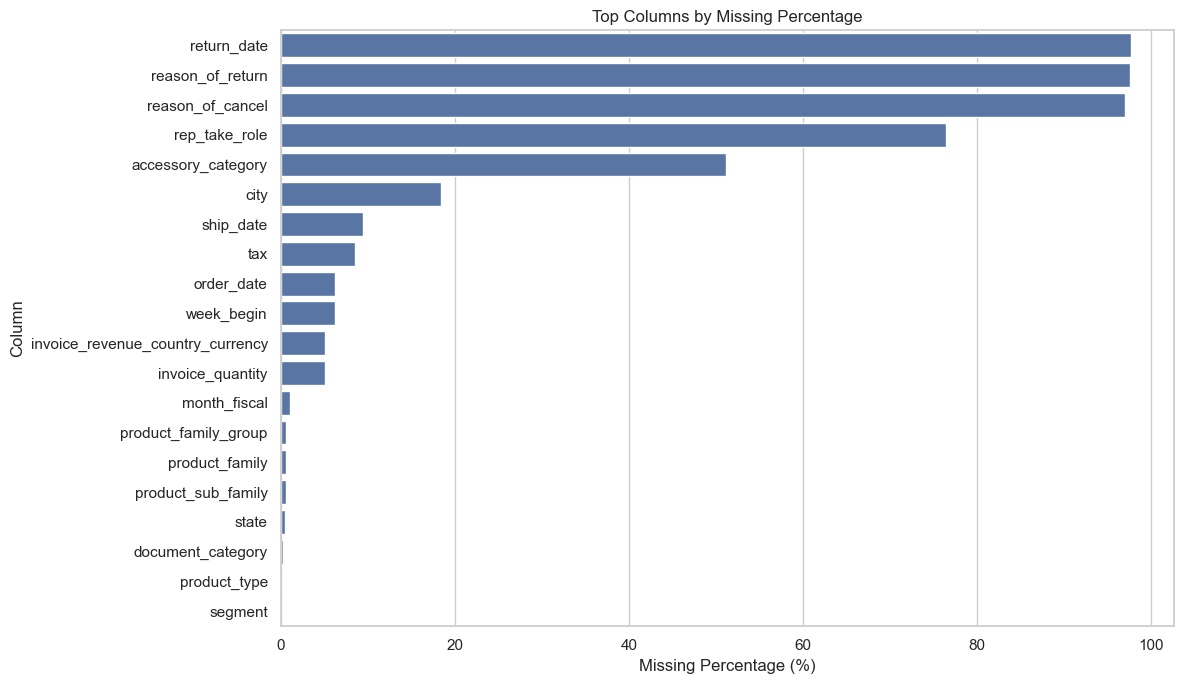

In [38]:
missing_plot = missing[missing["Missing Count"] > 0].head(20)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing_plot["Missing %"],
    y=missing_plot.index
)

plt.title("Top Columns by Missing Percentage")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Column")

plt.tight_layout()
plt.show()

In [39]:
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

Number of exact duplicate rows: 1358057
Duplicate percentage: 11.57 %


In [40]:
unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": [df[col].nunique(dropna=False) for col in df.columns]
})

display(unique_summary.sort_values("Unique Values", ascending=False))

,Column,Unique Values
27,margin,1658283
24,invoice_revenue_country_currency,622213
22,revenue,438012
26,cost,384439
25,tax,131192
10,city,32552
12,product_id,22296
13,product_name,21514
8,customer_id,9380
15,product_model,1714


# General Stats

In [41]:
numeric_columns = df.select_dtypes(include=np.number).columns

display(
    df[numeric_columns]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
order_units,11738282.0,1.32,11.44,-483.00,1.00,1.00,1.00,25161.0
revenue,11738282.0,443.84,2642.73,-227997.00,0.00,22.00,322.81,2781960.0
invoice_quantity,11144114.0,1.32,11.70,-483.00,1.00,1.00,1.00,25161.0
invoice_revenue_country_currency,11144114.0,475.92,2589.38,-227997.00,0.00,27.99,373.19,1094940.5
tax,10733838.0,34.37,135.89,-244.64,0.00,0.00,19.10,46504.7
cost,11738282.0,347.89,2342.15,-158741.10,0.01,9.59,207.80,1103494.0
margin,11738282.0,95.95,1592.95,-768243.94,-0.01,0.00,56.31,2781957.0


In [42]:
business_metrics = {
    "Total Revenue": df["revenue"].sum(),
    "Total Order Units": df["order_units"].sum(),
    "Total Invoice Quantity": df["invoice_quantity"].sum(),
    "Total Cost": df["cost"].sum(),
    "Total Margin": df["margin"].sum(),
    "Average Revenue per Record": df["revenue"].mean(),
    "Average Order Units per Record": df["order_units"].mean(),
    "Average Margin per Record": df["margin"].mean()
}

metrics_df = pd.DataFrame(
    business_metrics.items(),
    columns=["Metric", "Value"]
)

display(metrics_df)

,Metric,Value
0,Total Revenue,5.209965e+09
1,Total Order Units,1.545993e+07
2,Total Invoice Quantity,1.471680e+07
3,Total Cost,4.083684e+09
4,Total Margin,1.126250e+09
5,Average Revenue per Record,4.438439e+02
6,Average Order Units per Record,1.317052e+00
7,Average Margin per Record,9.594677e+01


In [43]:
total_revenue = df["revenue"].sum()
total_margin = df["margin"].sum()

overall_margin_percentage = (
    total_margin / total_revenue * 100
    if total_revenue != 0 else np.nan
)

print(f"Overall Margin Percentage: {overall_margin_percentage:.2f}%")

Overall Margin Percentage: 21.62%


## Distribution

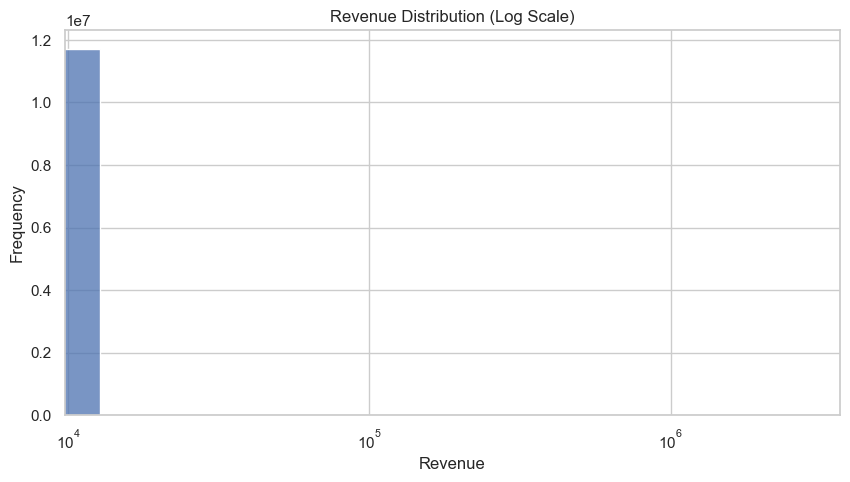

In [44]:
# Revenue Distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    df["revenue"].dropna(),
    bins=50
)

plt.xscale("log")
plt.title("Revenue Distribution (Log Scale)")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.show()

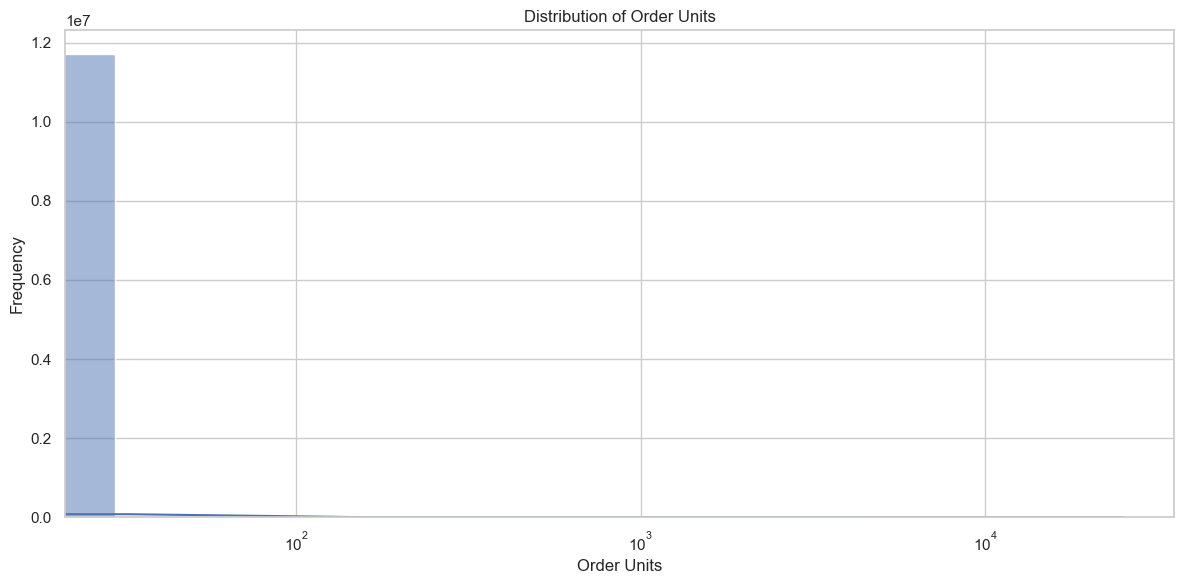

In [45]:
plt.figure(figsize=(12, 6))

sns.histplot(
    df["order_units"].dropna(),
    bins=50,
    kde=True
)
plt.xscale("log")
plt.title("Distribution of Order Units")
plt.xlabel("Order Units")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Outliers

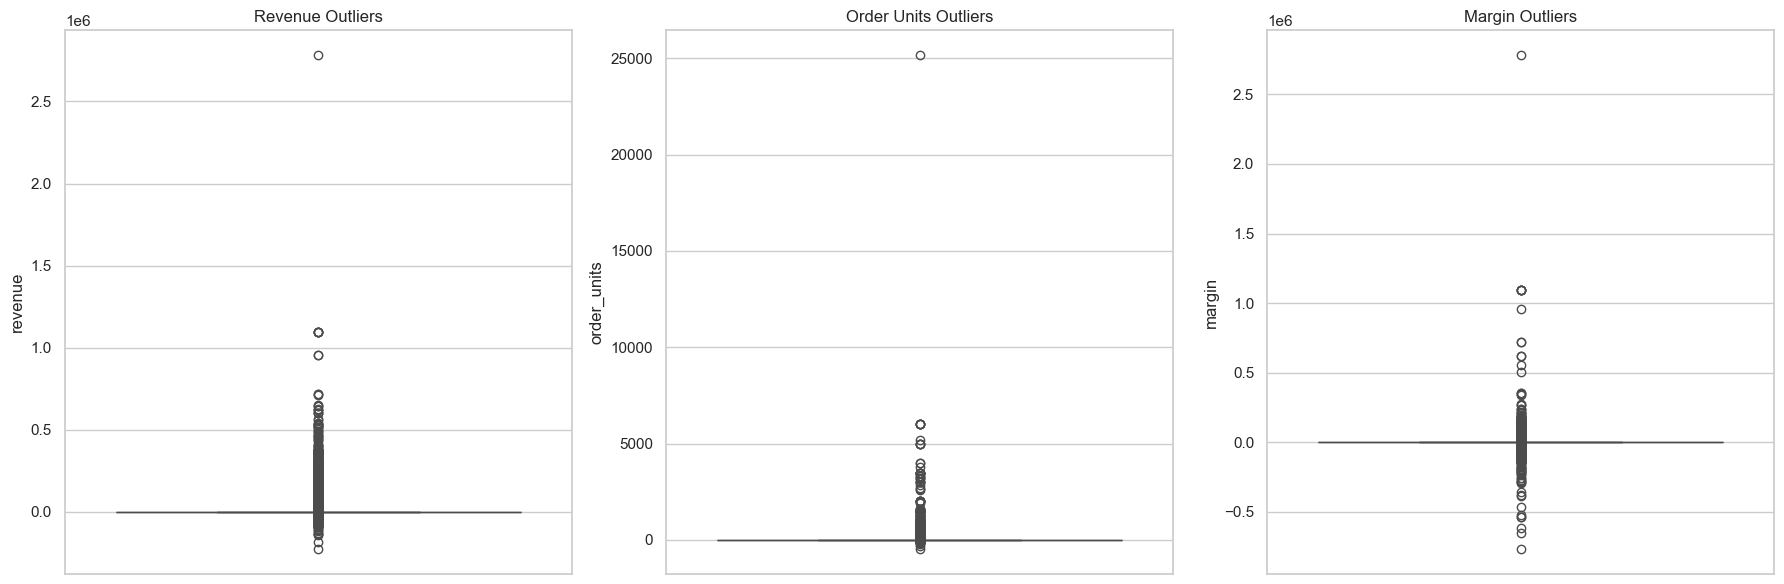

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.boxplot(y=df["revenue"], ax=axes[0])
axes[0].set_title("Revenue Outliers")

sns.boxplot(y=df["order_units"], ax=axes[1])
axes[1].set_title("Order Units Outliers")

sns.boxplot(y=df["margin"], ax=axes[2])
axes[2].set_title("Margin Outliers")

plt.tight_layout()
plt.show()

In [47]:
def outlier_summary(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    count = ((data[column] < lower) | (data[column] > upper)).sum()
    
    return {
        "Column": column,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count,
        "Outlier %": count / len(data) * 100
    }

outlier_results = pd.DataFrame([
    outlier_summary(df, col)
    for col in ["revenue", "order_units", "cost", "margin"]
])

display(outlier_results.round(2))

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,revenue,-484.22,807.03,2109702,17.97
1,order_units,1.00,1.00,1457981,12.42
2,cost,-311.68,519.49,2572333,21.91
3,margin,-84.49,140.79,2375922,20.24


# Categorical trends

In [48]:
categorical_columns = [
    "document_type",
    "document_category",
    "order_status",
    "product_line",
    "product_type",
    "segment",
    "country",
    "sales_channel",
    "price_tier"
]

for col in categorical_columns:
    if col in df.columns:
        print(f"\n--- {col} ---")
        display(df[col].value_counts(dropna=False).head(15))


--- document_type ---


document_type
Invoice             11290381
Return                281598
Order                 156557
Warranty Service        9746
Name: count, dtype: int64


--- document_category ---


document_category
Standard Invoice        9371131
Credit Memo             1175240
Sales Order             1010261
Return Order             155920
NaN                       21691
Manual Adjustment          3983
Doc Category Zulu            55
Doc Category Station          1
Name: count, dtype: int64


--- order_status ---


...

country
US    9664757
CA    2073525
Name: count, dtype: int64


--- sales_channel ---


sales_channel
Direct                         10272384
Partner Program                  837624
Marketplace                      238491
Clearance                        141416
Employee Program                  97136
Commercial Employee Program       84165
Consumer Program                  27679
Affinity Program                  20818
Route Glide Compass               18568
NaN                                   1
Name: count, dtype: int64


--- price_tier ---


price_tier
$0 - $299        8887145
$700  -  $999     478885
$1000 - $1299     450939
$2000+            330243
$500  -  $699     323216
$1300 - $1499     253054
$1500 - $1699     214545
$300  - $499      210951
$1700 - $1999     203327
$700 - $999       195000
$500 - $699        99132
$300 - $499        91844
NaN                    1
Name: count, dtype: int64

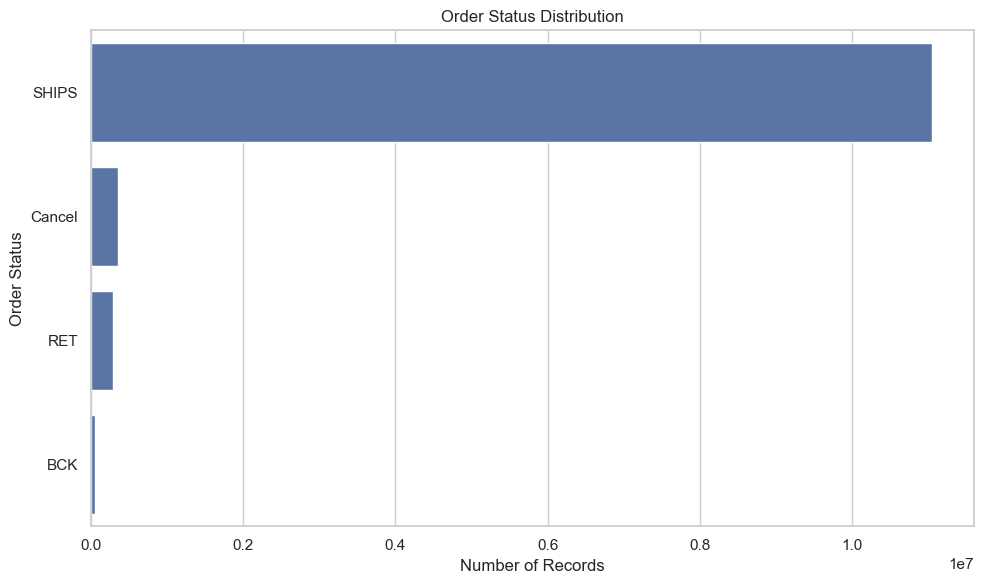

In [49]:
plt.figure(figsize=(10, 6))

order_status_counts = df["order_status"].value_counts()

sns.barplot(
    x=order_status_counts.values,
    y=order_status_counts.index
)

plt.title("Order Status Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Order Status")

plt.tight_layout()
plt.show()

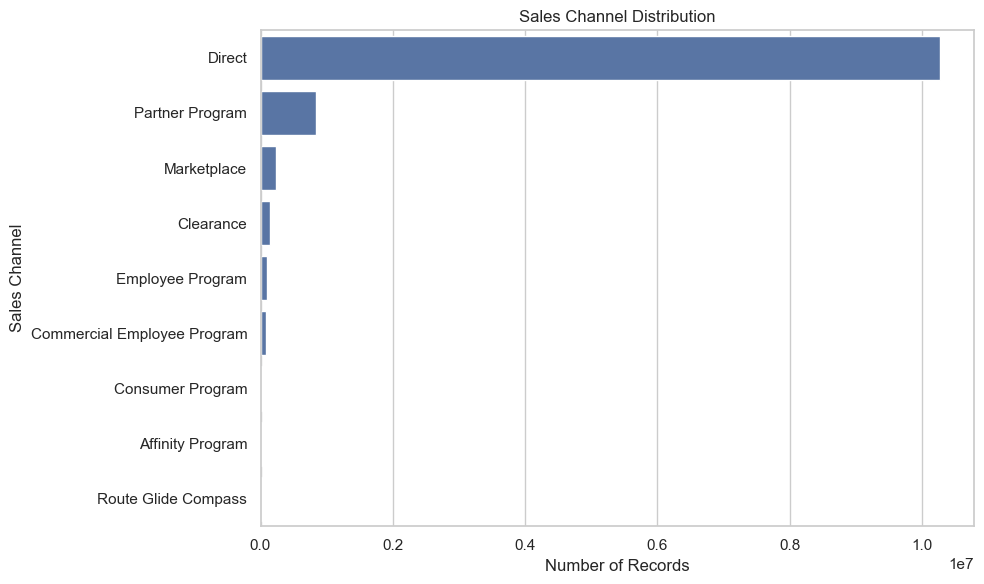

In [50]:
plt.figure(figsize=(10, 6))

channel_counts = df["sales_channel"].value_counts()

sns.barplot(
    x=channel_counts.values,
    y=channel_counts.index
)

plt.title("Sales Channel Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Sales Channel")

plt.tight_layout()
plt.show()

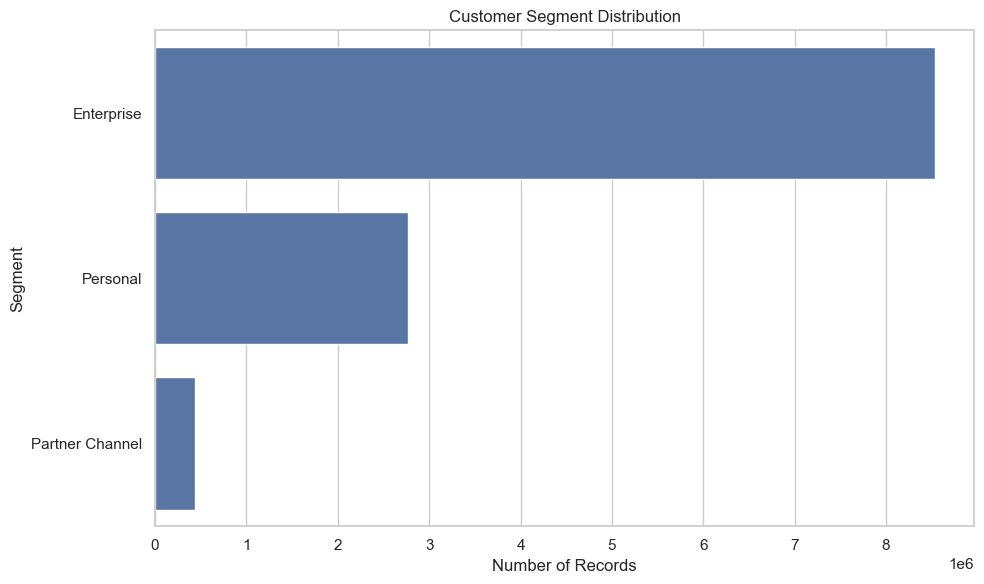

In [51]:
plt.figure(figsize=(10, 6))

segment_counts = df["segment"].value_counts()

sns.barplot(
    x=segment_counts.values,
    y=segment_counts.index
)

plt.title("Customer Segment Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Segment")

plt.tight_layout()
plt.show()

# Product analysis

In [52]:
top_products_revenue = (
    df.groupby("product_name", dropna=False)
      .agg(
          Revenue=("revenue", "sum"),
          Units=("order_units", "sum"),
          Margin=("margin", "sum")
      )
      .sort_values("Revenue", ascending=False)
      .head(15)
)

display(top_products_revenue.round(2))

,Revenue,Units,Margin
product_name,,,
W6 FOREST L98,60899312.54,44017.0,13370519.28
B5 BRIGHT H18,55083022.46,33785.0,19082355.24
T7 RADIUS I83,52177908.55,32849.0,13976124.27
66VU612WYH GARNET SKY,49230920.36,27516.0,17749590.11
85FQ673HIM THRIVE SUN,39595702.96,27936.0,10653236.83
48GA125NKC FOREST WAY,34283073.10,21458.0,8285608.82
INTEGRAL SOLSTICE J9 JULIET Y50 SKY 56XN,31479759.48,17040.0,11993447.33
03FN435BIU GARNET SUN,30955992.41,19755.0,7967012.62
CATALYST FRONTIER E8 JULIET D53 SUN 39RD,27672514.83,14174.0,10308801.24


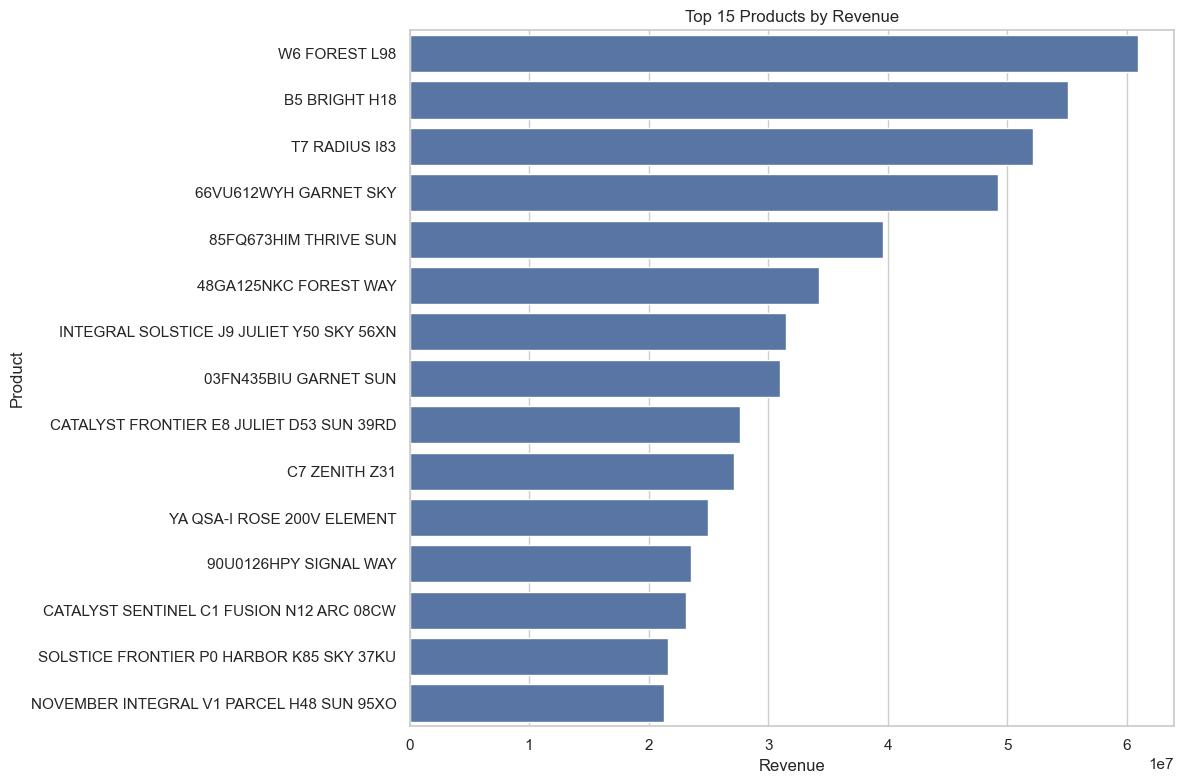

In [53]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_products_revenue.reset_index(),
    x="Revenue",
    y="product_name"
)

plt.title("Top 15 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

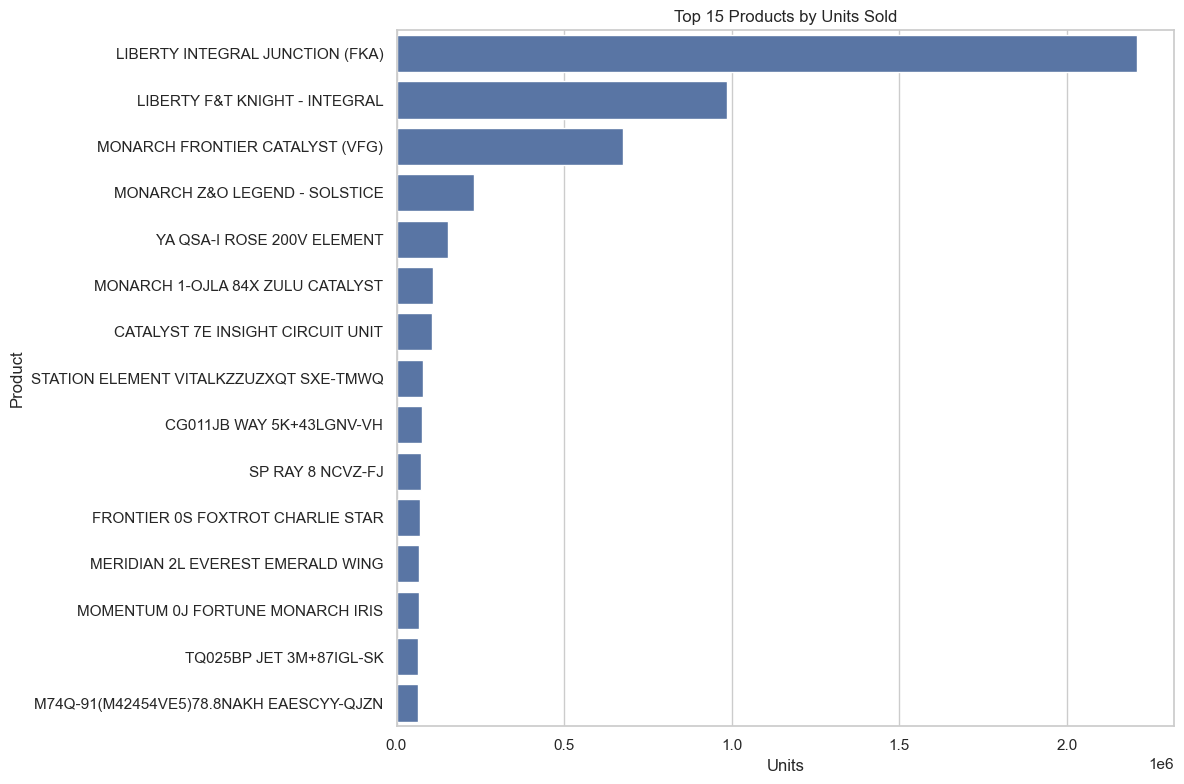

In [54]:
top_products_units = (
    df.groupby("product_name", dropna=False)["order_units"]
      .sum()
      .sort_values(ascending=False)
      .head(15)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_products_units.values,
    y=top_products_units.index
)

plt.title("Top 15 Products by Units Sold")
plt.xlabel("Units")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [55]:
product_line_summary = (
    df.groupby("product_line", dropna=False)
      .agg(
          Revenue=("revenue", "sum"),
          Units=("order_units", "sum"),
          Cost=("cost", "sum"),
          Margin=("margin", "sum"),
          Customers=("customer_id", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

product_line_summary["Margin %"] = (
    product_line_summary["Margin"] /
    product_line_summary["Revenue"] * 100
)

display(product_line_summary.round(2))

,Revenue,Units,Cost,Margin,Customers,Margin %
product_line,,,,,,
Series Kilo Plasma,7.934584e+08,515479.0,5.831686e+08,2.102897e+08,2946,26.50
Series Meridian Romeo,7.516853e+08,422766.0,6.091716e+08,1.425137e+08,3549,18.96
Series Ocean Volt,5.250956e+08,420626.0,3.611111e+08,1.639844e+08,3186,31.23
Series Tango Spring,3.013698e+08,340427.0,2.368172e+08,6.455263e+07,2261,21.42
Series Charlie Talon,2.535101e+08,180084.0,2.028144e+08,5.069568e+07,2216,20.00
...,...,...,...,...,...,...
Series Eagle Radius,-2.730000e+02,-2.0,-3.819800e+02,1.088500e+02,2,-39.87
Series Parcel Valley,-3.543400e+02,-38.0,-3.475300e+02,-4.510000e+00,7,1.27
Series Quantum Sentinel,-7.610000e+02,-47.0,-2.103230e+03,1.344170e+03,3,-176.63


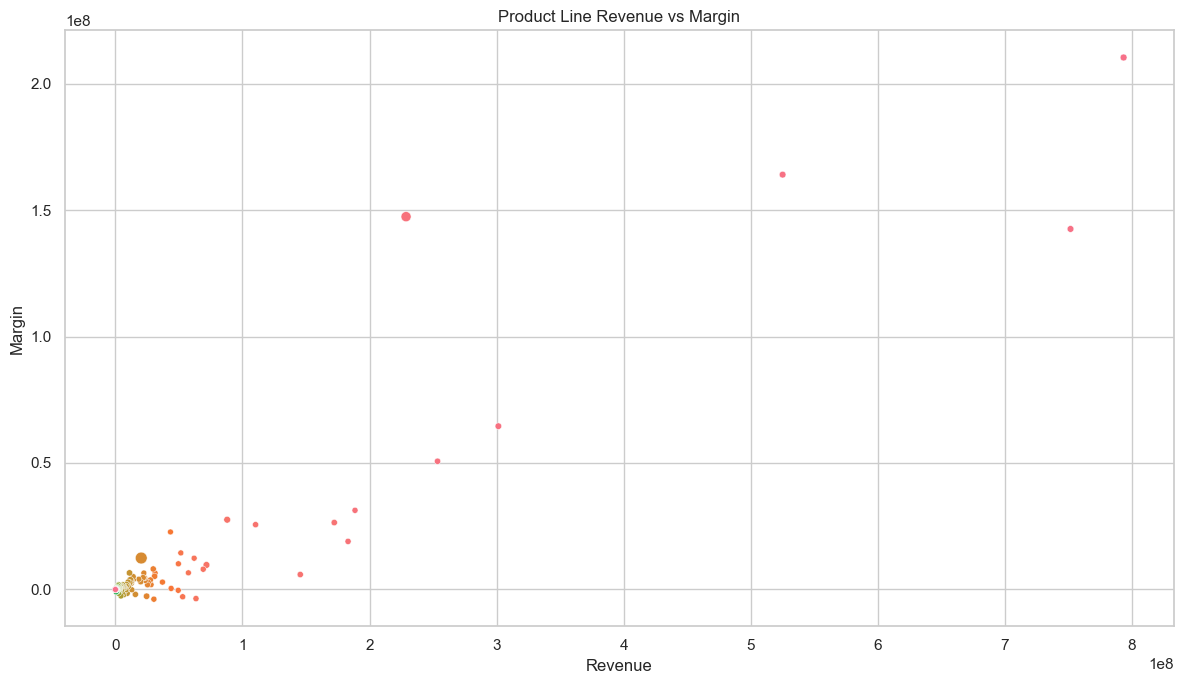

In [56]:
plot_data = product_line_summary.reset_index()

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_data,
    x="Revenue",
    y="Margin",
    size="Units",
    hue="product_line",
    legend=False
)

plt.title("Product Line Revenue vs Margin")
plt.xlabel("Revenue")
plt.ylabel("Margin")

plt.tight_layout()
plt.show()

# Product Line

In [57]:
product_line_summary = (
    df.groupby(
        "product_line",
        dropna=False
    )
    .agg(
        Revenue=("revenue", "sum"),
        Units=("order_units", "sum"),
        Cost=("cost", "sum"),
        Margin=("margin", "sum"),
        Products=("product_id", "nunique")
    )
)

product_line_summary["Margin %"] = (
    product_line_summary["Margin"] /
    product_line_summary["Revenue"] * 100
)

product_line_summary = (
    product_line_summary
    .sort_values(
        "Revenue",
        ascending=False
    )
)

display(
    product_line_summary.round(2)
)

,Revenue,Units,Cost,Margin,Products,Margin %
product_line,,,,,,
Series Kilo Plasma,7.934584e+08,515479.0,5.831686e+08,2.102897e+08,1030,26.50
Series Meridian Romeo,7.516853e+08,422766.0,6.091716e+08,1.425137e+08,1926,18.96
Series Ocean Volt,5.250956e+08,420626.0,3.611111e+08,1.639844e+08,1441,31.23
Series Tango Spring,3.013698e+08,340427.0,2.368172e+08,6.455263e+07,479,21.42
Series Charlie Talon,2.535101e+08,180084.0,2.028144e+08,5.069568e+07,345,20.00
...,...,...,...,...,...,...
Series Eagle Radius,-2.730000e+02,-2.0,-3.819800e+02,1.088500e+02,2,-39.87
Series Parcel Valley,-3.543400e+02,-38.0,-3.475300e+02,-4.510000e+00,4,1.27
Series Quantum Sentinel,-7.610000e+02,-47.0,-2.103230e+03,1.344170e+03,2,-176.63


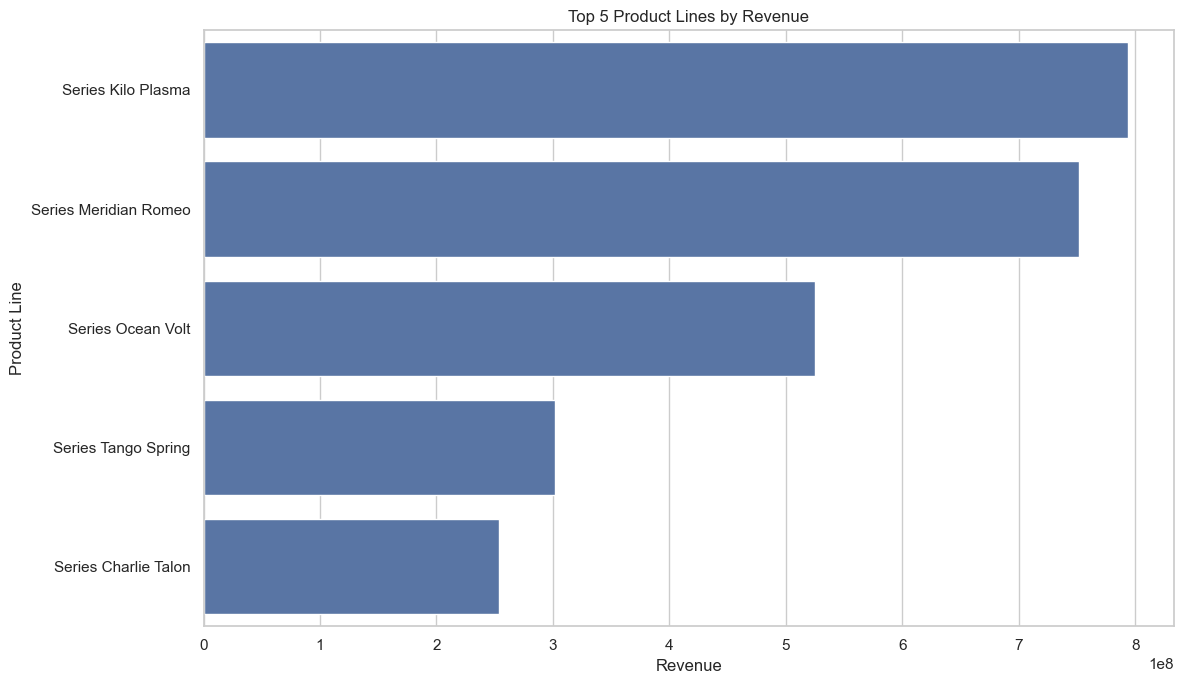

In [58]:
top_5_product_lines = (
    product_line_summary
    .sort_values("Revenue", ascending=False)
    .head(5)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_5_product_lines.reset_index(),
    x="Revenue",
    y="product_line",
    order=top_5_product_lines.index
)

plt.title("Top 5 Product Lines by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()

# Product Family

In [59]:
family_summary = (
    df.groupby(
        "product_family",
        dropna=False
    )
    .agg(
        Revenue=("revenue", "sum"),
        Units=("order_units", "sum"),
        Cost=("cost", "sum"),
        Margin=("margin", "sum"),
        Products=("product_id", "nunique")
    )
)

family_summary["Margin %"] = (
    family_summary["Margin"] /
    family_summary["Revenue"] * 100
)

family_summary = (
    family_summary
    .sort_values(
        "Revenue",
        ascending=False
    )
)

display(
    family_summary.round(2)
)

,Revenue,Units,Cost,Margin,Products,Margin %
product_family,,,,,,
Product Family Frame Road,1.451119e+09,1039535.0,1.045084e+09,4.060356e+08,3091,27.98
Product Family Solar Peak,1.056694e+09,627128.0,8.527108e+08,2.039835e+08,2340,19.30
Product Family Knight Thrive,5.830382e+08,740790.0,4.860947e+08,9.694346e+07,2020,16.63
Product Family Lima Line,4.436635e+08,282167.0,3.861838e+08,5.747963e+07,737,12.96
Product Family Romeo Iris,3.440302e+08,3827706.0,1.728972e+08,1.711328e+08,1830,49.74
Product Family Terra Rose,3.054189e+08,311829.0,2.798264e+08,2.559254e+07,458,8.38
Product Family Titan Onset,2.537313e+08,309001.0,2.007275e+08,5.300389e+07,542,20.89
Product Family Lantern Orbit,1.731032e+08,370738.0,1.870344e+08,-1.393121e+07,1053,-8.05
Product Family Portal Bridge,1.098692e+08,65829.0,1.036372e+08,6.232030e+06,136,5.67


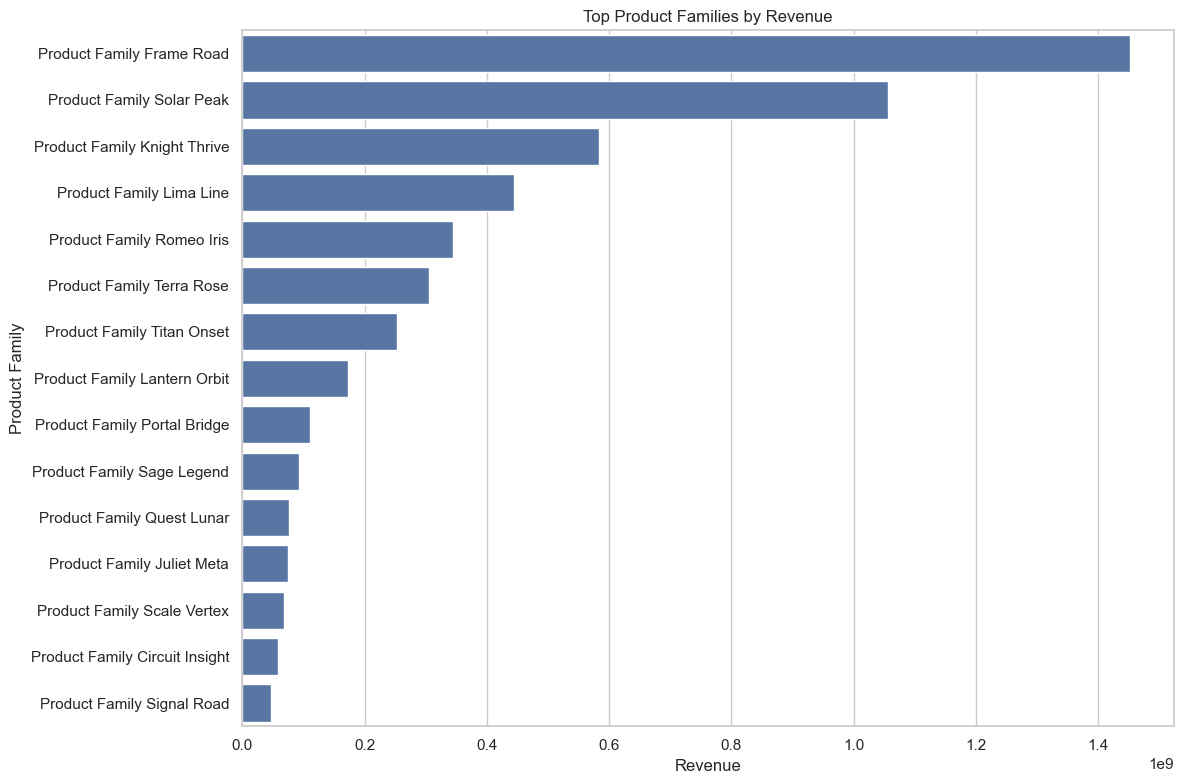

In [60]:
top_families = (
    family_summary
    .head(15)
    .reset_index()
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_families,
    x="Revenue",
    y="product_family"
)

plt.title(
    "Top Product Families by Revenue"
)

plt.xlabel("Revenue")
plt.ylabel("Product Family")

plt.tight_layout()
plt.show()

# Segment Analysis

In [61]:
segment_summary = (
    df.groupby(
        "segment",
        dropna=False
    )
    .agg(
        Revenue=("revenue", "sum"),
        Units=("order_units", "sum"),
        Cost=("cost", "sum"),
        Margin=("margin", "sum"),
        Records=("segment", "size")
    )
)

segment_summary["Margin %"] = (
    segment_summary["Margin"] /
    segment_summary["Revenue"] * 100
)

segment_summary = (
    segment_summary
    .sort_values(
        "Revenue",
        ascending=False
    )
)

display(
    segment_summary.round(2)
)

,Revenue,Units,Cost,Margin,Records,Margin %
segment,,,,,,
Enterprise,3.845393e+09,11166811.0,2.863578e+09,9.817856e+08,8536801,25.53
Personal,1.316509e+09,3732505.0,1.166719e+09,1.497895e+08,2765586,11.38
Partner Channel,4.624891e+07,555359.0,5.232076e+07,-6.071898e+06,433339,-13.13
NaN,1.814188e+06,5258.0,1.067111e+06,7.470770e+05,2556,41.18


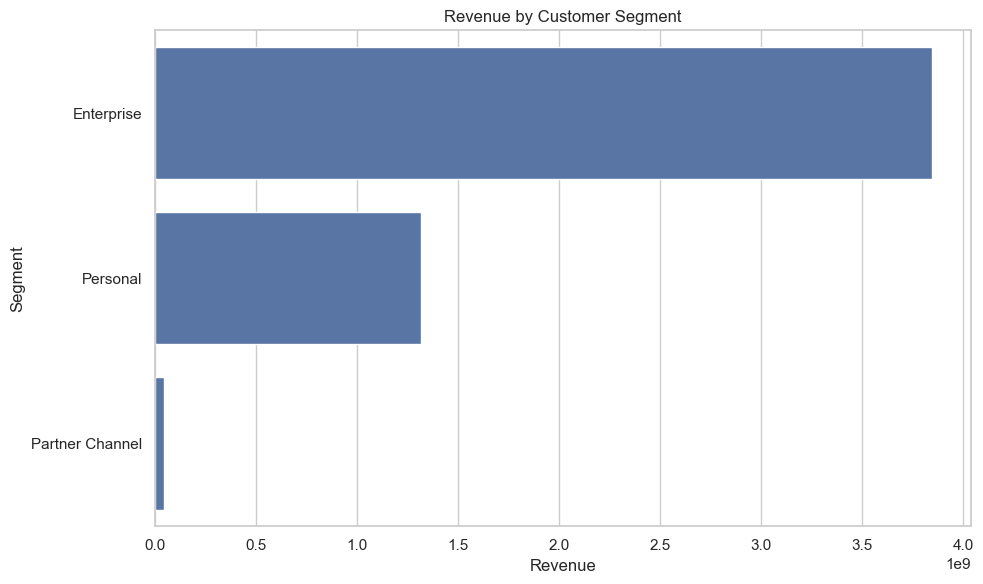

In [62]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary.reset_index(),
    x="Revenue",
    y="segment"
)

plt.title(
    "Revenue by Customer Segment"
)

plt.xlabel("Revenue")
plt.ylabel("Segment")

plt.tight_layout()
plt.show()

In [63]:
#Financial Summary
financial_summary = pd.DataFrame({
    "Metric": [
        "Revenue",
        "Cost",
        "Margin"
    ],
    "Value": [
        df["revenue"].sum(),
        df["cost"].sum(),
        df["margin"].sum()
    ]
})

display(
    financial_summary.round(2)
)

,Metric,Value
0,Revenue,5.209965e+09
1,Cost,4.083684e+09
2,Margin,1.126250e+09


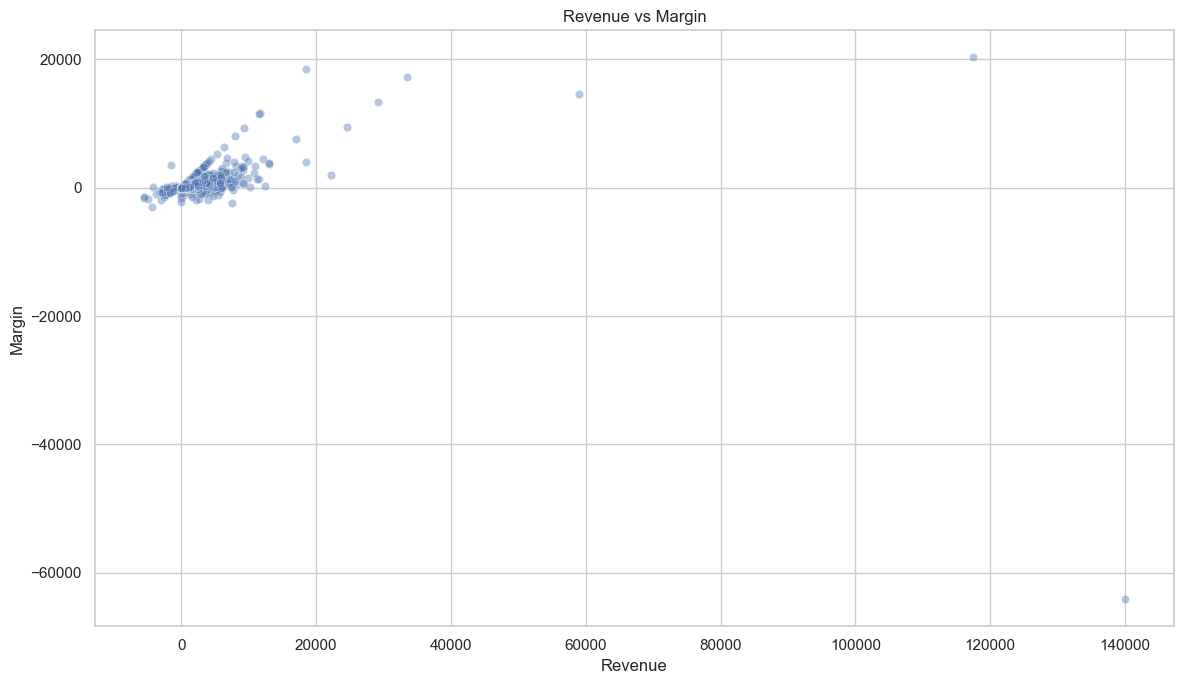

In [64]:
sample_df = df.sample(
    min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=sample_df,
    x="revenue",
    y="margin",
    alpha=0.4
)

plt.title(
    "Revenue vs Margin"
)

plt.xlabel("Revenue")
plt.ylabel("Margin")

plt.tight_layout()
plt.show()

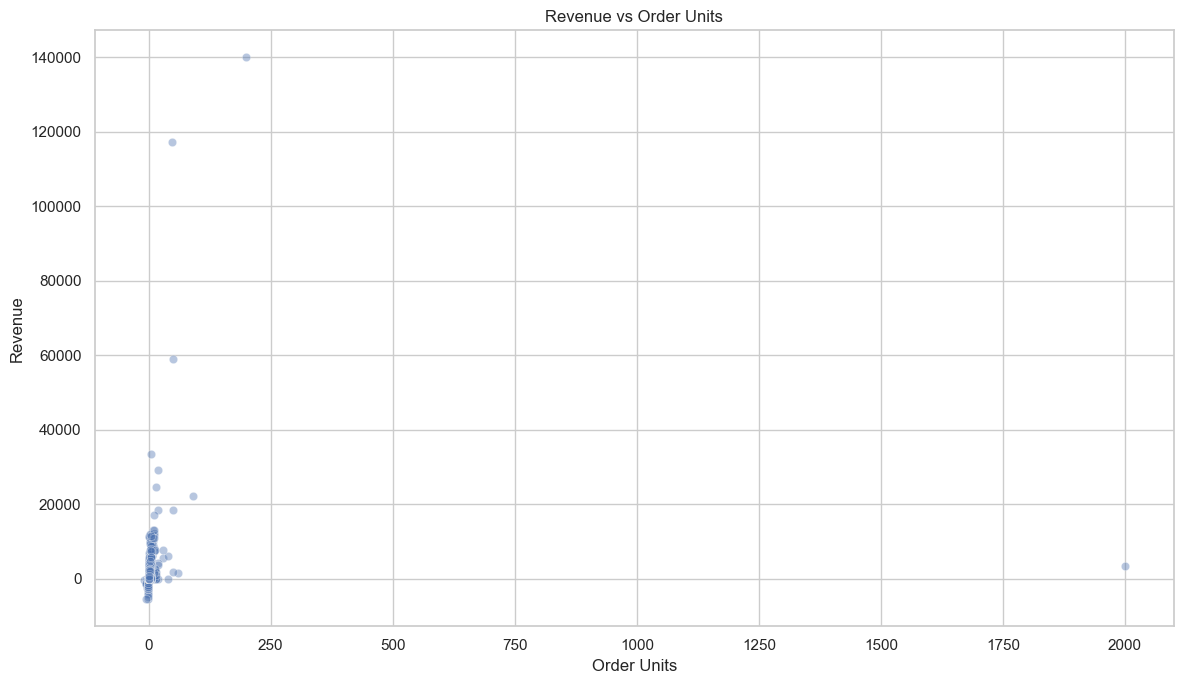

In [65]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=sample_df,
    x="order_units",
    y="revenue",
    alpha=0.4
)

plt.title(
    "Revenue vs Order Units"
)

plt.xlabel("Order Units")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

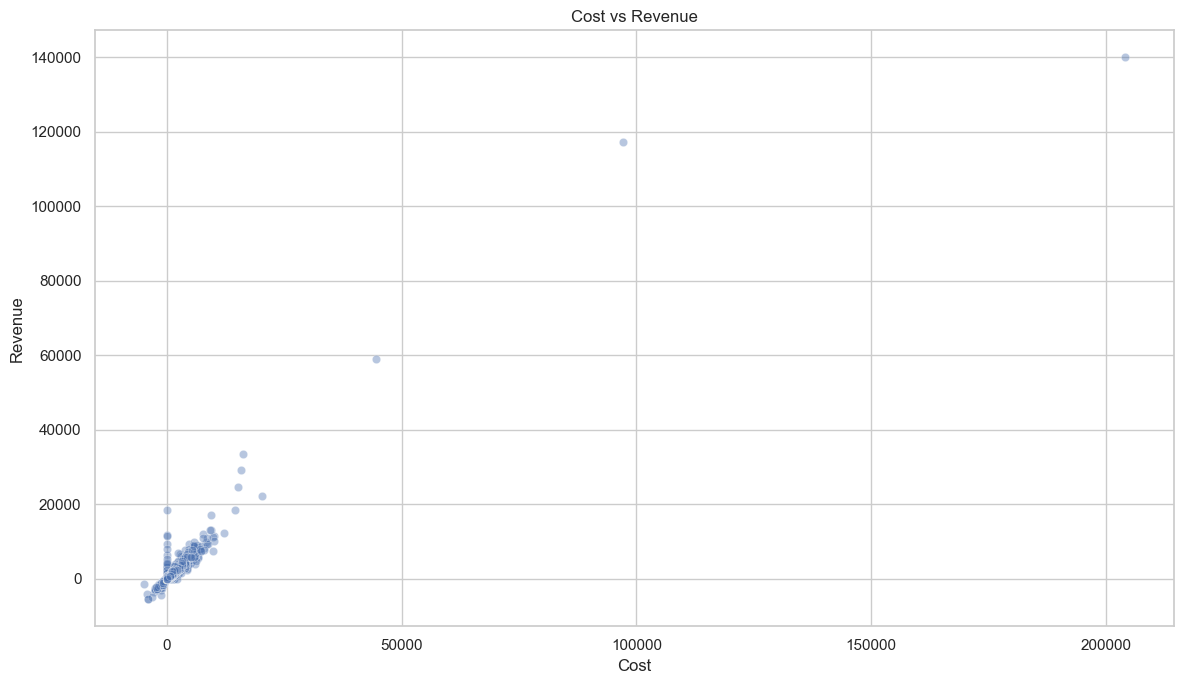

In [66]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=sample_df,
    x="cost",
    y="revenue",
    alpha=0.4
)

plt.title(
    "Cost vs Revenue"
)

plt.xlabel("Cost")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

# Correlation

In [67]:
correlation_columns = [
    "order_units",
    "revenue",
    "invoice_quantity",
    "invoice_revenue_country_currency",
    "tax",
    "cost",
    "margin"
]

correlation_columns = [
    col
    for col in correlation_columns
    if col in df.columns
]

corr = df[
    correlation_columns
].corr()

display(
    corr.round(2)
)

,order_units,revenue,invoice_quantity,invoice_revenue_country_currency,tax,cost,margin
order_units,1.00,0.32,1.00,0.33,0.16,0.35,0.03
revenue,0.32,1.00,0.34,0.99,0.59,0.80,0.48
invoice_quantity,1.00,0.34,1.00,0.33,0.16,0.35,0.02
invoice_revenue_country_currency,0.33,0.99,0.33,1.00,0.62,0.86,0.35
tax,0.16,0.59,0.16,0.62,1.00,0.45,0.34
cost,0.35,0.80,0.35,0.86,0.45,1.00,-0.14
margin,0.03,0.48,0.02,0.35,0.34,-0.14,1.00


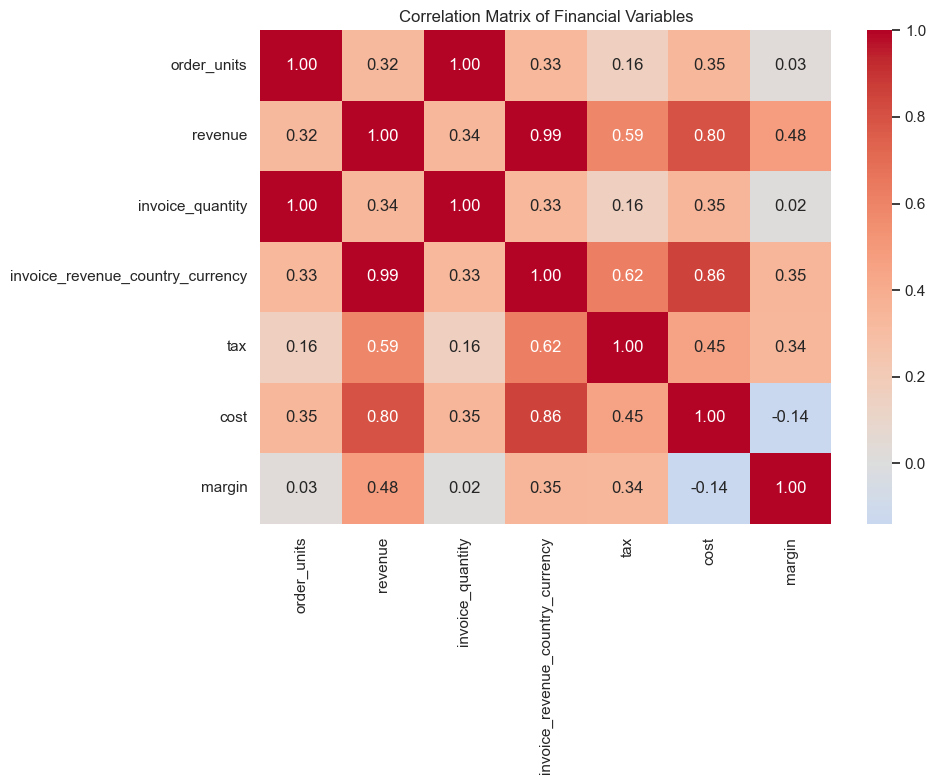

In [68]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Matrix of Financial Variables"
)

plt.tight_layout()
plt.show()

# Time series

In [69]:
period_summary = (
    df.groupby(
        "fiscal_period"
    )
    .agg(
        Revenue=("revenue", "sum"),
        Units=("order_units", "sum"),
        Cost=("cost", "sum"),
        Margin=("margin", "sum"),
        Orders=("order_date", "count")
    )
    .sort_index()
)

period_summary["Margin %"] = (
    period_summary["Margin"] /
    period_summary["Revenue"] * 100
)

display(
    period_summary.round(2)
)

,Revenue,Units,Cost,Margin,Orders,Margin %
fiscal_period,,,,,,
FY24Q1,3.229389e+08,978824.0,2.602879e+08,6.265086e+07,758160,19.40
FY24Q2,3.565395e+08,1115992.0,2.919819e+08,6.455753e+07,890687,18.11
FY24Q3,3.999858e+08,1430947.0,3.333464e+08,6.662695e+07,1120634,16.66
FY24Q4,3.247709e+08,1062706.0,2.531649e+08,7.160600e+07,816636,22.05
FY25Q1,3.552471e+08,1075484.0,2.772519e+08,7.797789e+07,796208,21.95
FY25Q2,3.882392e+08,1263947.0,3.185607e+08,6.967842e+07,967728,17.95
FY25Q3,4.521128e+08,1491643.0,3.781287e+08,7.398385e+07,1184055,16.36
FY25Q4,3.908142e+08,1189520.0,3.020046e+08,8.880943e+07,887568,22.72
FY26Q1,4.017078e+08,1113925.0,2.985240e+08,1.031838e+08,795846,25.69


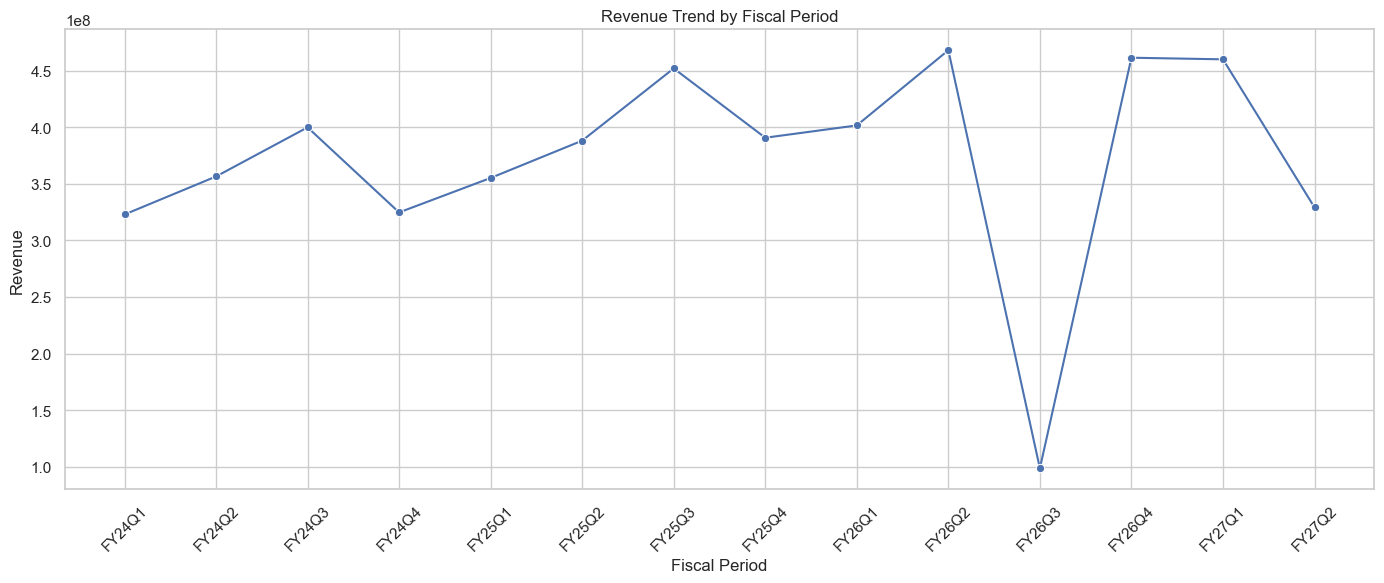

In [70]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=period_summary,
    x=period_summary.index,
    y="Revenue",
    marker="o"
)

plt.title(
    "Revenue Trend by Fiscal Period"
)

plt.xlabel("Fiscal Period")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

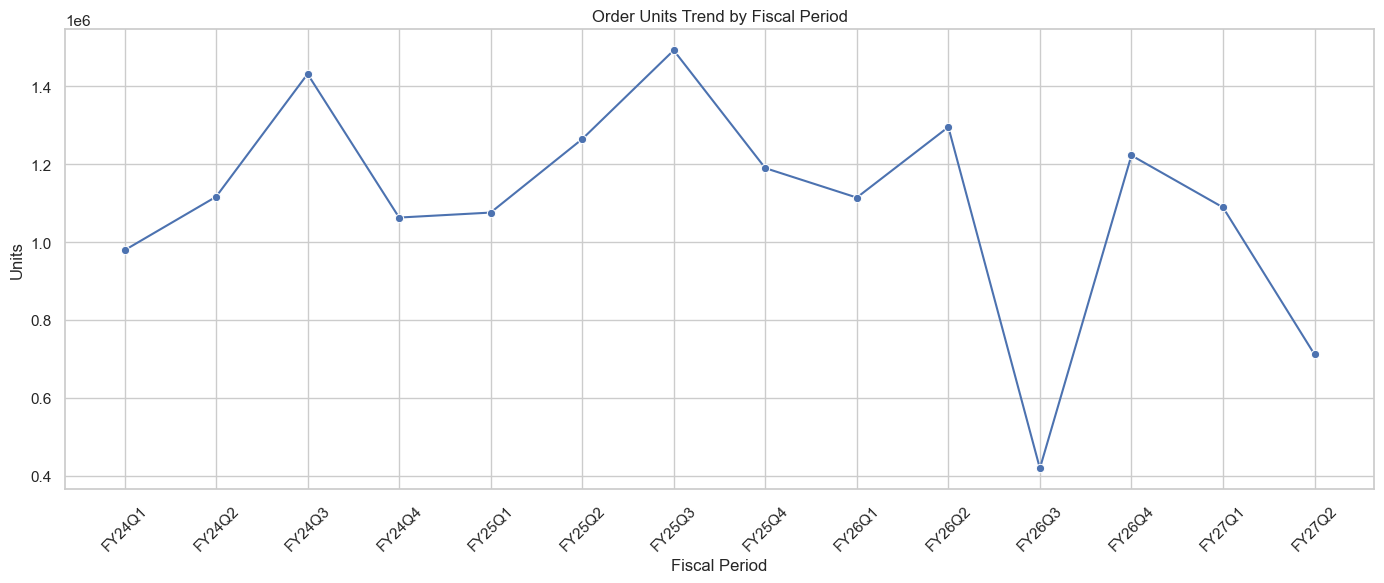

In [71]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=period_summary,
    x=period_summary.index,
    y="Units",
    marker="o"
)

plt.title(
    "Order Units Trend by Fiscal Period"
)

plt.xlabel("Fiscal Period")
plt.ylabel("Units")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

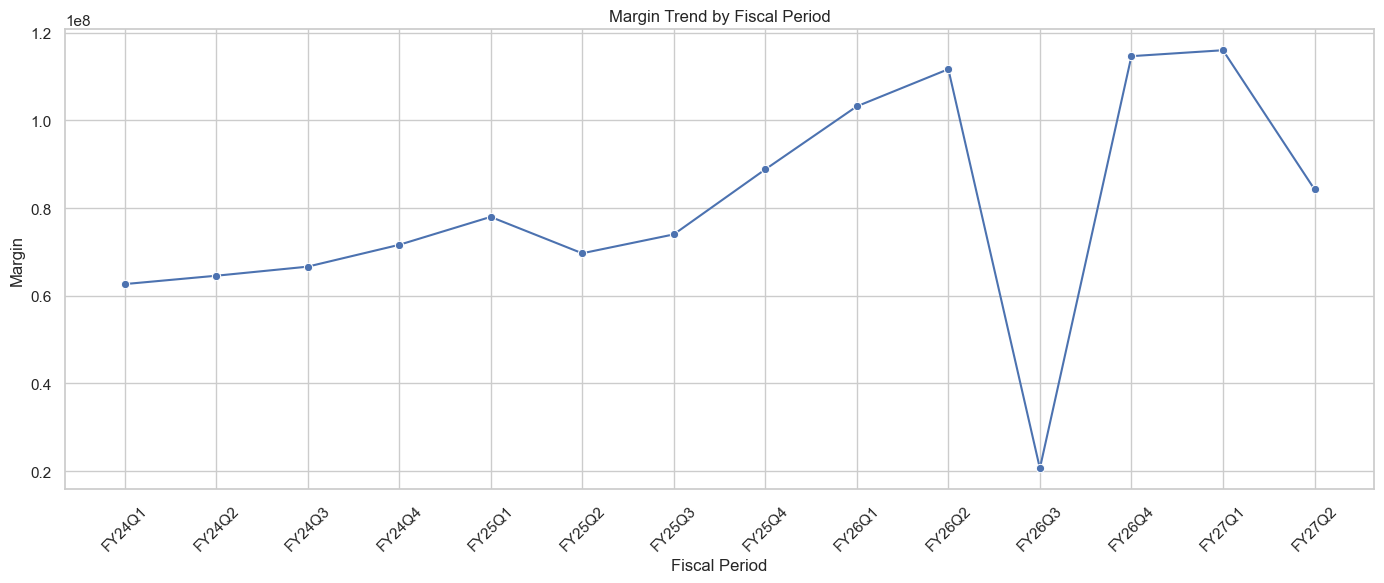

In [72]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=period_summary,
    x=period_summary.index,
    y="Margin",
    marker="o"
)

plt.title(
    "Margin Trend by Fiscal Period"
)

plt.xlabel("Fiscal Period")
plt.ylabel("Margin")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Monthly

In [73]:
monthly_summary = (
    df.groupby(
        df["order_date"].dt.to_period("M")
    )
    .agg(
        Revenue=("revenue", "sum"),
        Units=("order_units", "sum"),
        Cost=("cost", "sum"),
        Margin=("margin", "sum")
    )
)

monthly_summary.index = (
    monthly_summary.index
    .to_timestamp()
)

display(
    monthly_summary.head()
)

,Revenue,Units,Cost,Margin
order_date,,,,
2023-04-01,9.299597e+07,270786.0,7.475652e+07,1.823937e+07
2023-05-01,1.201667e+08,372148.0,9.788793e+07,2.227871e+07
2023-06-01,1.097762e+08,335890.0,8.764345e+07,2.213277e+07
2023-07-01,1.121591e+08,352142.0,9.054195e+07,2.161713e+07
2023-08-01,1.346340e+08,429828.0,1.126999e+08,2.193412e+07


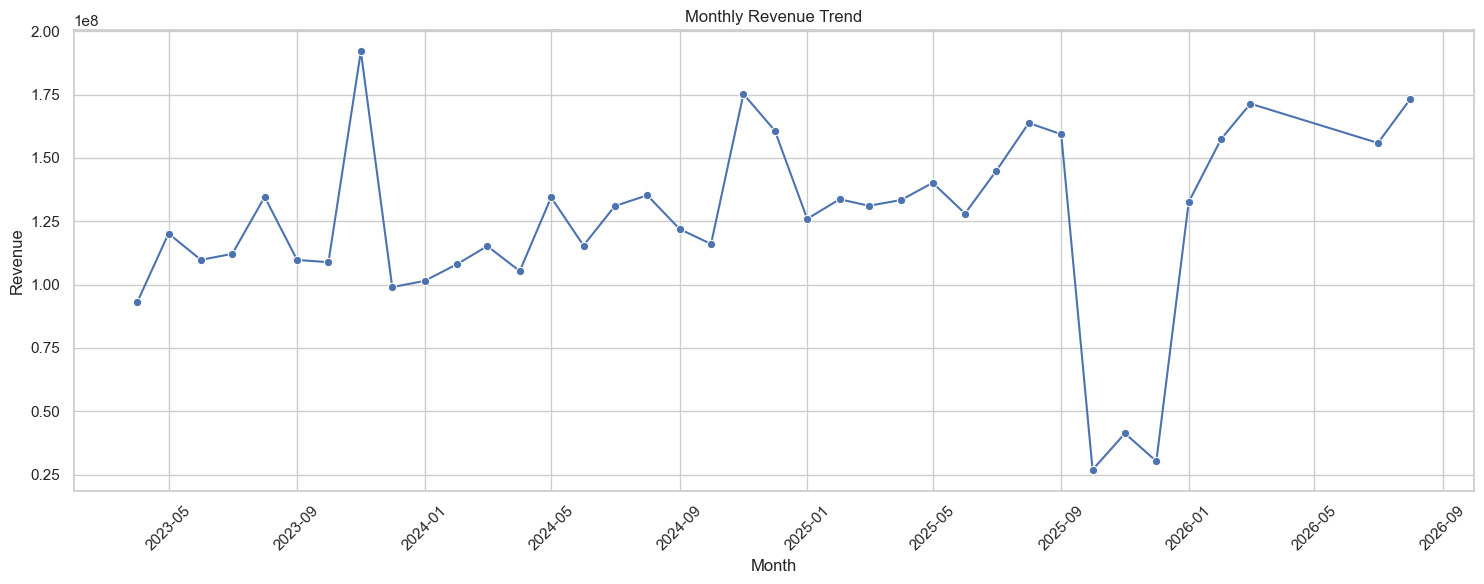

In [74]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_summary,
    x=monthly_summary.index,
    y="Revenue",
    marker="o"
)

plt.title(
    "Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

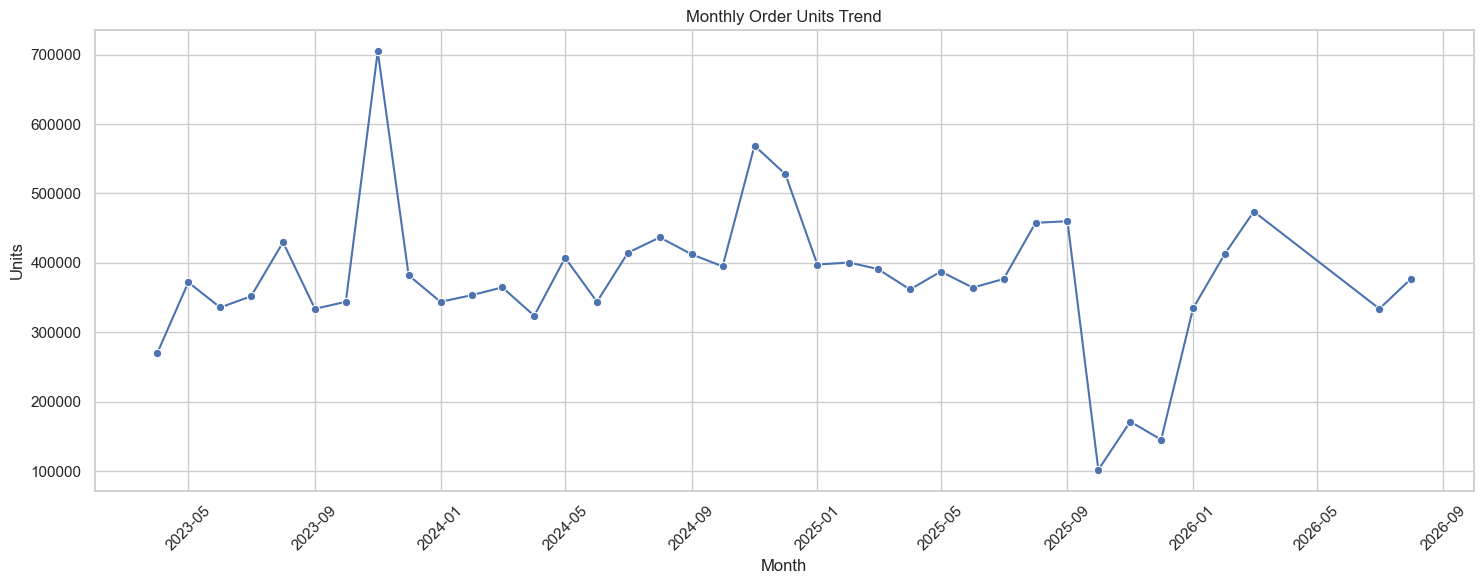

In [75]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_summary,
    x=monthly_summary.index,
    y="Units",
    marker="o"
)

plt.title(
    "Monthly Order Units Trend"
)

plt.xlabel("Month")
plt.ylabel("Units")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Returns

In [76]:
total_records = len(df)

returned_records = (
    df["return_date"]
    .notna()
    .sum()
)

return_rate = (
    returned_records /
    total_records * 100
)

print(
    "Returned Records:",
    returned_records
)

print(
    f"Return Rate: {return_rate:.2f}%"
)

Returned Records: 265897
Return Rate: 2.27%


In [77]:
return_reasons = (
    df["reason_of_return"]
    .value_counts(
        dropna=False
    )
    .head(15)
)

display(
    return_reasons
)

reason_of_return
NaN                                        11456941
return by Product quality issue               66529
Return: Customer Satisfaction                 65461
Return: Unauthorized                          51960
Return: Contract Termination                  21537
Return: Defective                             18230
Return: Customer Error                        14403
Return-Customer Accomodation                  13380
return by Delivery Date delay                  7558
Return: Sales Error                            6485
Return-Customer Accomodation - open box        3182
Marketing problem                              2719
Return: Damaged in transit                     2212
Return: Late Cancel.(After Ship)               2050
Return-Incorrect shipment                      1743
Name: count, dtype: int64

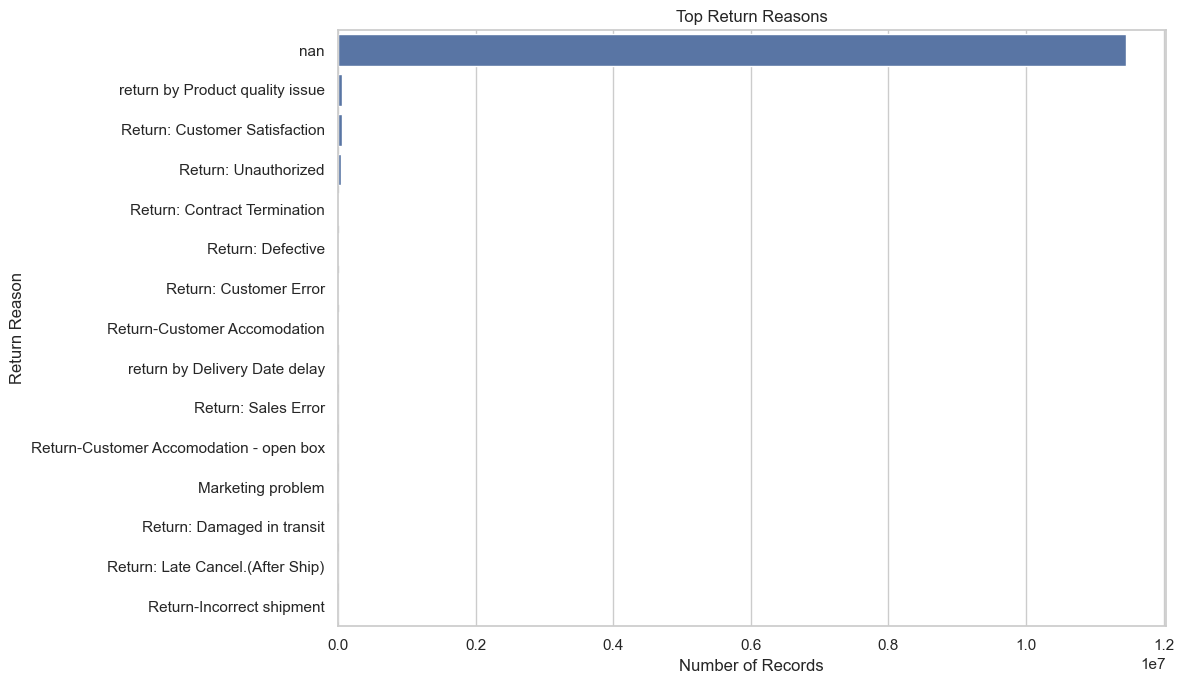

In [78]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=return_reasons.values,
    y=return_reasons.index.astype(str)
)

plt.title(
    "Top Return Reasons"
)

plt.xlabel("Number of Records")
plt.ylabel("Return Reason")

plt.tight_layout()
plt.show()

In [79]:
return_by_product_line = (
    df.groupby("product_line")
    .agg(
        Total_Records=("product_line", "size"),
        Returned=(
            "return_date",
            lambda x: x.notna().sum()
        )
    )
)

return_by_product_line[
    "Return Rate %"
] = (
    return_by_product_line["Returned"] /
    return_by_product_line["Total_Records"] *
    100
)

return_by_product_line = (
    return_by_product_line
    .sort_values(
        "Return Rate %",
        ascending=False
    )
)

display(
    return_by_product_line.round(2)
)

,Total_Records,Returned,Return Rate %
product_line,,,
Series Focus Foxtrot,12,12,100.00
Series Eagle Radius,2,2,100.00
Series Plus Spring,1,1,100.00
Series Quantum Sentinel,38,38,100.00
Series Surge Alpha,47,37,78.72
...,...,...,...
Series River Cloud,1,0,0.00
Series Gate Unity,21,0,0.00
Series Glide Motion,1,0,0.00


# Cancellation

In [80]:
cancelled_records = (
    df["reason_of_cancel"]
    .notna()
    .sum()
)

cancellation_rate = (
    cancelled_records /
    len(df) * 100
)

print(
    "Cancelled Records:",
    cancelled_records
)

print(
    f"Cancellation Rate: "
    f"{cancellation_rate:.2f}%"
)

Cancelled Records: 353233
Cancellation Rate: 3.01%


In [81]:
cancel_reasons = (
    df["reason_of_cancel"]
    .value_counts(
        dropna=False
    )
    .head(15)
)

display(
    cancel_reasons
)

reason_of_cancel
NaN                                    11385049
Order cancelled by customer request      184693
Assigned by the System (Internal)         89988
Others                                    35695
Order cancelled due to system error       30692
Cancel for Credit Issue                    4892
FS - Insufficient Inventory                4199
Cancel for Fraud Manual Review             1117
Cancel for Failed Authorization            1031
FS Cancel - EOL                             254
FS Cancel - Customer                        227
不符合客服一次开箱换货标准被撤单                            107
No Payment Within 14 Days                    68
其它                                           62
FTC Cancellation                             49
Name: count, dtype: int64

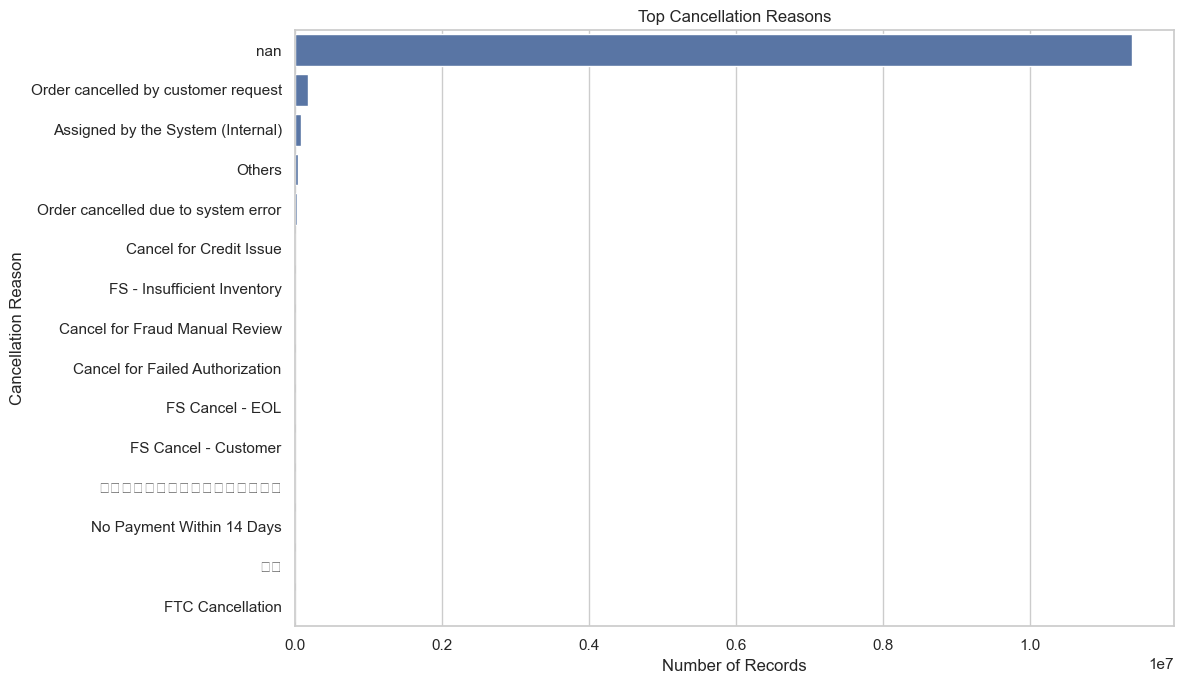

In [82]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=cancel_reasons.values,
    y=cancel_reasons.index.astype(str)
)

plt.title(
    "Top Cancellation Reasons"
)

plt.xlabel("Number of Records")
plt.ylabel("Cancellation Reason")

plt.tight_layout()
plt.show()

# Price Tiers

In [83]:
price_tier_summary = (
    df.groupby(
        "price_tier",
        dropna=False
    )
    .agg(
        Revenue=("revenue", "sum"),
        Units=("order_units", "sum"),
        Cost=("cost", "sum"),
        Margin=("margin", "sum")
    )
)

price_tier_summary["Margin %"] = (
    price_tier_summary["Margin"] /
    price_tier_summary["Revenue"] * 100
)

display(
    price_tier_summary
    .sort_values(
        "Revenue",
        ascending=False
    )
    .round(2)
)

,Revenue,Units,Cost,Margin,Margin %
price_tier,,,,,
$2000+,1.054697e+09,378296.0,7.314499e+08,3.232462e+08,30.65
$1000 - $1299,7.545139e+08,658557.0,6.093363e+08,1.451735e+08,19.24
$0 - $299,5.819109e+08,11440121.0,4.099821e+08,1.719237e+08,29.54
$700 - $999,5.811161e+08,694330.0,5.147484e+08,6.635728e+07,11.42
$1300 - $1499,4.927132e+08,353302.0,3.753782e+08,1.173350e+08,23.81
$1700 - $1999,4.668275e+08,254385.0,3.372796e+08,1.295465e+08,27.75
$1500 - $1699,4.593025e+08,287951.0,3.405715e+08,1.187303e+08,25.85
$500 - $699,2.989115e+08,491164.0,2.990231e+08,-1.116265e+05,-0.04
$700 - $999,2.502223e+08,294268.0,2.159779e+08,3.424436e+07,13.69


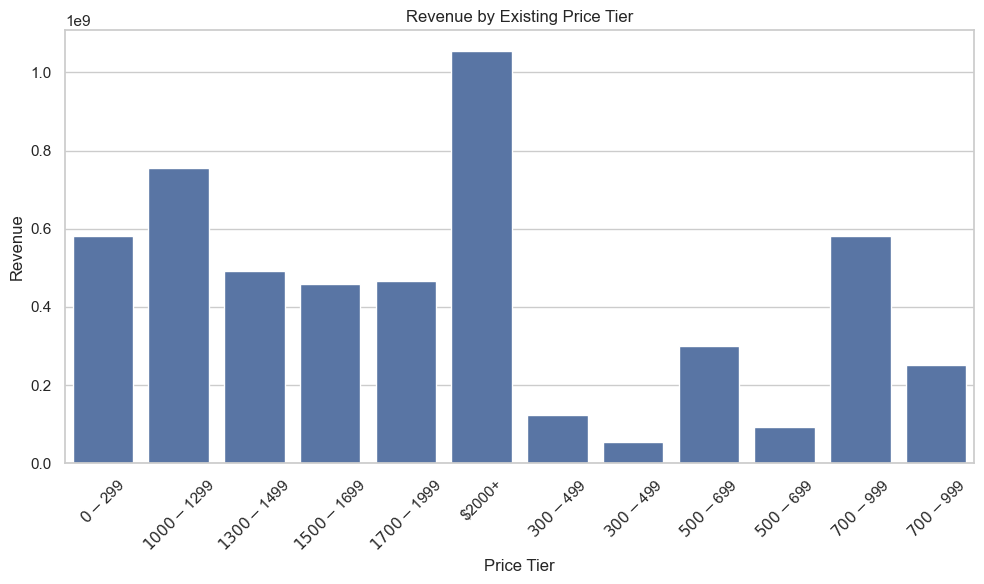

In [84]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=price_tier_summary.reset_index(),
    x="price_tier",
    y="Revenue"
)

plt.title(
    "Revenue by Existing Price Tier"
)

plt.xlabel("Price Tier")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

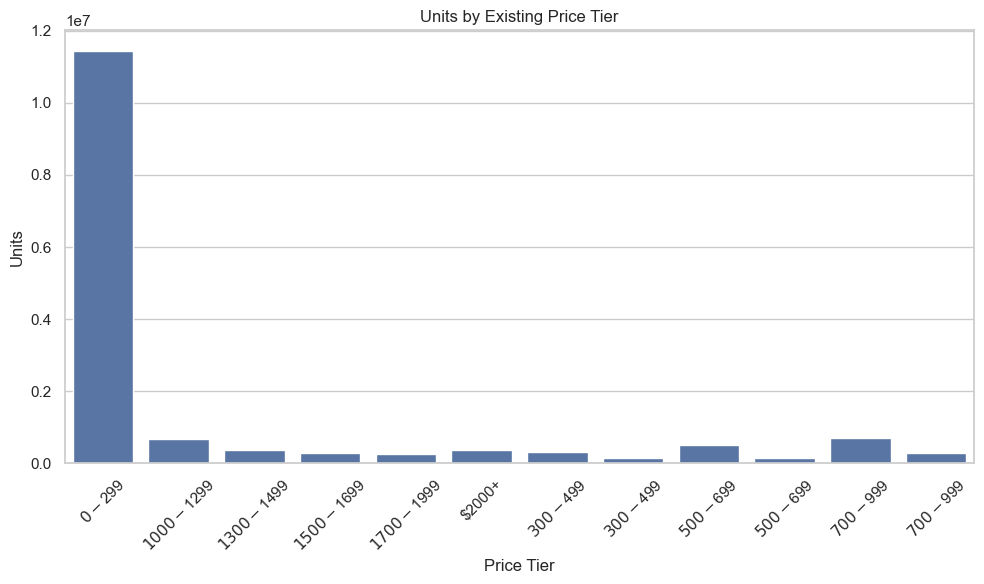

In [85]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=price_tier_summary.reset_index(),
    x="price_tier",
    y="Units"
)

plt.title(
    "Units by Existing Price Tier"
)

plt.xlabel("Price Tier")
plt.ylabel("Units")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [86]:
segment_product = pd.pivot_table(
    df,
    values="revenue",
    index="segment",
    columns="product_line",
    aggfunc="sum",
    fill_value=0
)

display(
    segment_product.round(2)
)

product_line,Series Alpha Matrix,Series Alpha Vantage,Series Apex Azure,Series Arc Curve,Series Arc Global,Series Arrow Canyon,Series Arrow Grid,Series Base Fusion,Series Base Noble,Series Base Uplift,Series Blaze Parcel,Series Bloom Force,Series Bloom Forest,Series Bloom Relay,Series Bloom Unit,Series Boost Emerald,Series Boost Thrive,Series Boost Wave,Series Bravo Dynamo,Series Bravo Pulse,Series Bridge Alpha,Series Bridge Flow,Series Bridge Grace,Series Bridge Titan,Series Bright Drive,Series Broad Pivot,Series Broad Zone,Series Canyon Arrow,Series Canyon Garnet,Series Canyon Legend,Series Canyon Talon,Series Cargo Coast,Series Catalyst Dynamo,Series Catalyst Icon,Series Catalyst Legend,Series Catalyst Uniform,Series Cedar Vigor,Series Century Nova,Series Charlie Silver,Series Charlie Talon,Series Charlie Triumph,Series Circuit Frame,Series Circuit Gate,Series Civic Foxtrot,Series Civic November,Series Clarity Coast,Series Clarity Delta,Series Coast Icon,Series Cobalt Spire,Series Cobalt Storm,Series Cobalt Thrive,Series Crest Bright,Series Crystal Harmony,Series Crystal Spark,Series Curve Spring,Series Curve Tango,Series Cypress Insight,Series Cypress Integral,Series Cypress Kinetic,Series Data Edge,Series Data Liberty,Series Dawn Emerald,Series Dawn Focus,Series Delta Junction,Series Delta Spark,Series Delta Stream,Series Direct Iris,Series Drive Compass,Series Dynamo Motion,Series Dynamo Plus,Series Dynamo Rocket,Series Eagle Radius,Series Echo Bridge,Series Echo India,Series Echo Tango,Series Edge Blaze,Series Edge Venture,Series Element Sync,Series Elite Insight,Series Elite Motion,Series Ember Silver,Series Emerald Crystal,Series Emerald Hotel,Series Engage Sage,Series Everest Helix,Series Excel Terra,Series Excel Turbo,Series Falcon Link,Series Flare Ground,Series Flare Sync,Series Flow Cobalt,Series Flow Xray,Series Focus Foxtrot,Series Force Scout,Series Force Vantage,Series Forest Emerald,Series Forest Pulse,Series Forest Sky,Series Fortune Fusion,Series Fortune Ray,Series Foxtrot Talon,Series Frame Juliet,Series Frontier Sky,Series Frontier Titan,Series Fusion Clarity,Series Fusion Hawk,Series Galaxy Romeo,Series Galaxy Tango,Series Garnet Impact,Series Gate Unity,Series Glide Canyon,Series Glide Helix,Series Glide Line,Series Glide Motion,Series Global Momentum,Series Global Rapid,Series Global Star,Series Global Titan,Series Golf Echo,Series Golf Emerald,Series Golf Fortune,Series Grace Ember,Series Grace Reach,Series Grace Solstice,Series Grand Line,Series Grand Mike,Series Grand Romeo,Series Grand Sky,Series Grand Wing,Series Grid Global,Series Grid Willow,Series Ground Solar,Series Guide Uniform,Series Harbor Bridge,Series Harbor Data,Series Harmony Harbor,Series Hawk Vertex,Series Horizon Hawk,Series Horizon Ridge,Series Hotel Vantage,Series Icon Maple,Series Impact Arc,Series Impact Broad,Series Impact Uplift,Series Insight Horizon,Series Jade Broad,Series Jade Drive,Series Jet Terra,Series Juliet Compass,Series Karma Quebec,Series Karma Quest,Series Karma Zulu,Series Kilo Ember,Series Kilo Plasma,Series Kilo Triumph,Series Kinetic Maple,Series Kinetic Orbit,Series Kinetic Star,Series Knight Ridge,Series Lattice Elite,Series Liberty Iris,Series Light Ground,Series Light Line,Series Light Stream,Series Line Dynamo,Series Line Onset,Series Line Orbit,Series Link India,Series Logic Grand,Series Logic Karma,Series Logic Peak,Series Logic Ridge,Series Logic Wave,Series Lunar Arrow,Series Lunar Eagle,Series Lunar Portal,Series Magnum Foxtrot,Series Maple Curve,Series Maple Reach,Series Matrix Apex,Series Matrix Ray,Series Meridian Rally,Series Meridian Romeo,Series Meta Oasis,Series Meta Spark,Series Meta Titan,Series Mike Scout,Series Mint Direct,Series Mint Yankee,Series Momentum Cedar,Series Momentum Coast,Series Motion Venture,Series Nexus Excel,Series Nexus Harbor,Series Noble Bolt,Series Noble Spire,Series Nova Portal,Series Oasis Eagle,Series Oasis Icon,Series Oasis Wing,Series Ocean Knight,Series Ocean V

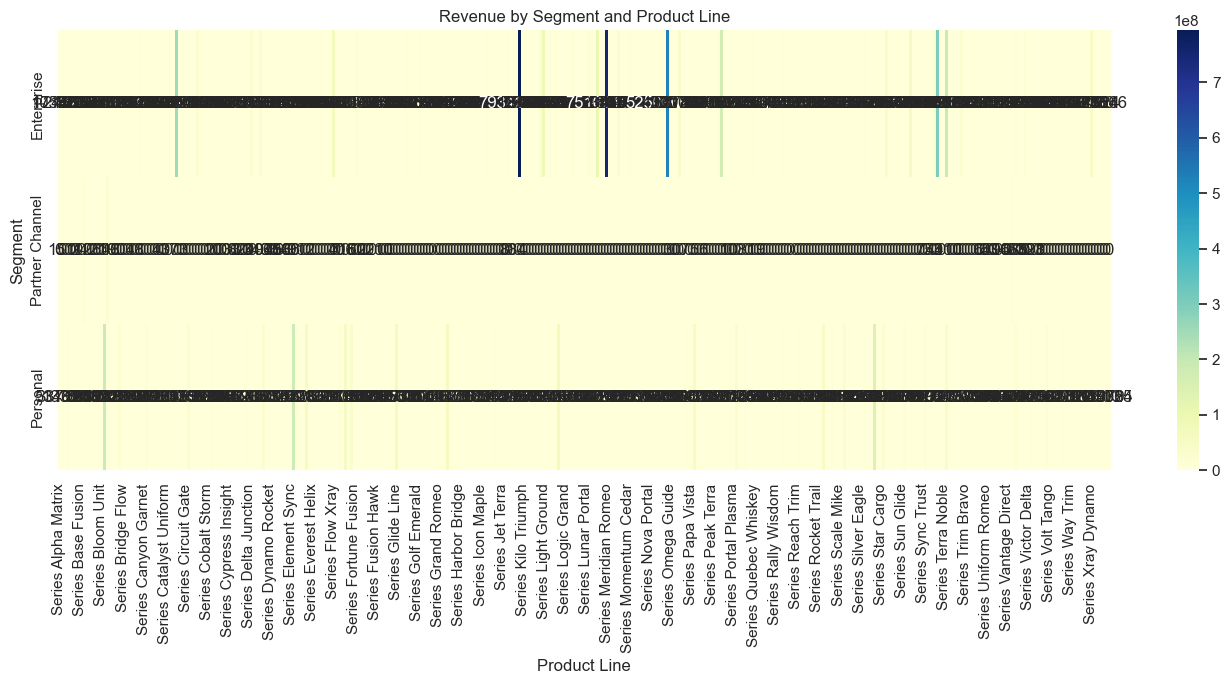

In [87]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    segment_product,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title(
    "Revenue by Segment and Product Line"
)

plt.xlabel("Product Line")
plt.ylabel("Segment")

plt.tight_layout()
plt.show()

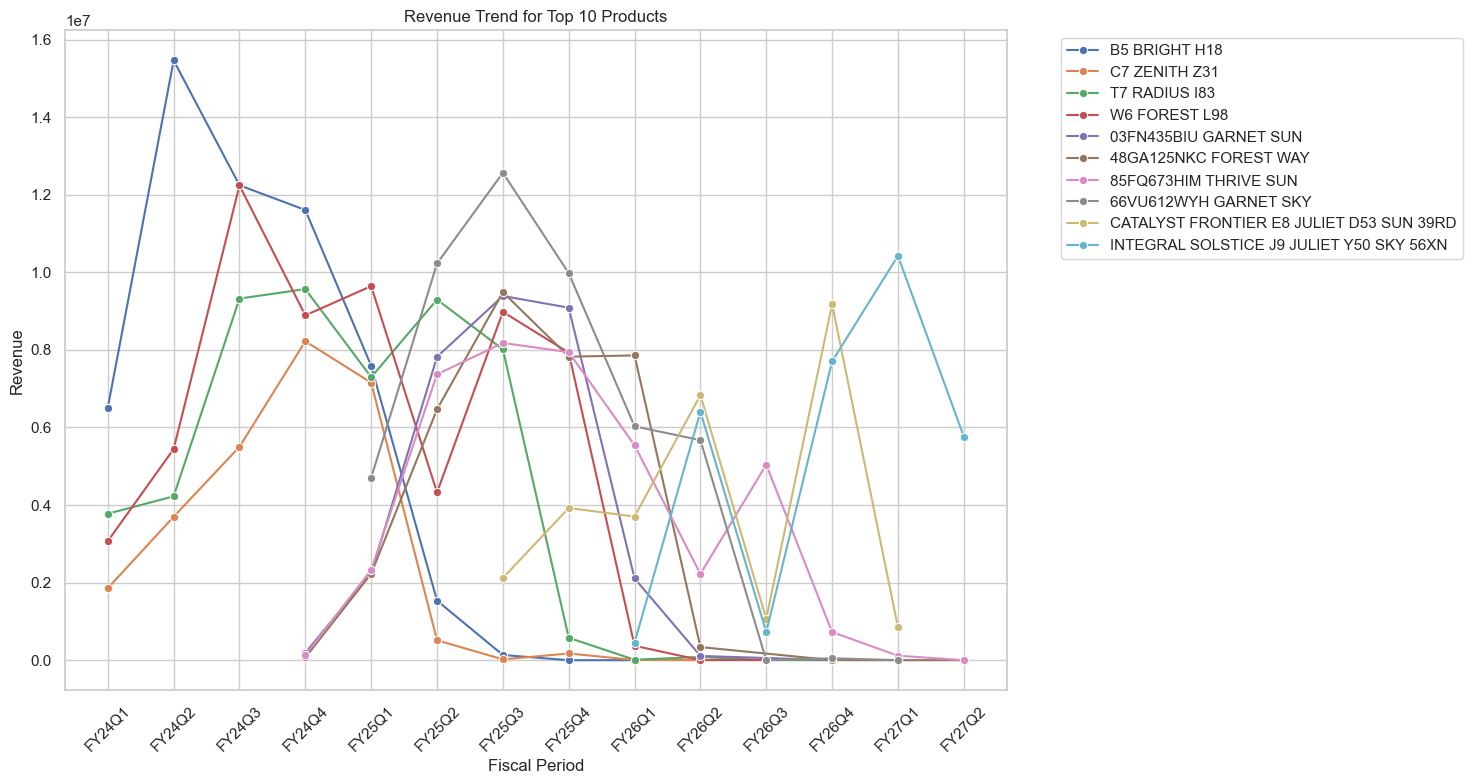

In [88]:
top_product_names = (
    df.groupby("product_name")["revenue"]
    .sum()
    .nlargest(10)
    .index
)

product_time = (
    df[
        df["product_name"]
        .isin(top_product_names)
    ]
    .groupby(
        ["fiscal_period", "product_name"]
    )["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(15, 8))

sns.lineplot(
    data=product_time,
    x="fiscal_period",
    y="revenue",
    hue="product_name",
    marker="o"
)

plt.title(
    "Revenue Trend for Top 10 Products"
)

plt.xlabel("Fiscal Period")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [89]:
total_revenue = df["revenue"].sum()
total_units = df["order_units"].sum()
total_cost = df["cost"].sum()
total_margin = df["margin"].sum()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Units",
        "Total Cost",
        "Total Margin",
        "Margin %",
        "Unique Products",
        "Unique Product Lines",
        "Unique Product Families",
        "Unique Segments",
        "Return Rate %",
        "Cancellation Rate %"
    ],
    
    "Value": [
        total_revenue,
        total_units,
        total_cost,
        total_margin,
        total_margin / total_revenue * 100,
        df["product_id"].nunique(),
        df["product_line"].nunique(),
        df["product_family"].nunique(),
        df["segment"].nunique(),
        df["return_date"].notna().mean() * 100,
        df["reason_of_cancel"].notna().mean() * 100
    ]
})

display(
    kpi_summary.round(2)
)

,KPI,Value
0,Total Revenue,5.209965e+09
1,Total Units,1.545993e+07
2,Total Cost,4.083684e+09
3,Total Margin,1.126250e+09
4,Margin %,2.162000e+01
5,Unique Products,2.229600e+04
6,Unique Product Lines,3.500000e+02
7,Unique Product Families,2.100000e+01
8,Unique Segments,3.000000e+00
9,Return Rate %,2.270000e+00


In [90]:
quality_results = []

for col in df.columns:
    
    missing_count = df[col].isna().sum()
    unique_count = df[col].nunique(
        dropna=False
    )
    
    quality_results.append({
        "Column": col,
        "Data Type": str(df[col].dtype),
        "Missing Count": missing_count,
        "Missing %": round(
            missing_count / len(df) * 100,
            2
        ),
        "Unique Values": unique_count
    })

data_quality_report = (
    pd.DataFrame(quality_results)
    .sort_values(
        "Missing %",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    data_quality_report
)

,Column,Data Type,Missing Count,Missing %,Unique Values
0,return_date,datetime64[ns],11472385,97.73,1187
1,reason_of_return,object,11456941,97.60,58
2,reason_of_cancel,object,11385049,96.99,30
3,rep_take_role,object,8969110,76.41,4
4,accessory_category,object,6008536,51.19,60
5,city,object,2163366,18.43,32552
6,ship_date,datetime64[ns],1109096,9.45,1239
7,tax,float64,1004444,8.56,131192
8,order_date,datetime64[ns],729657,6.22,1157
9,week_begin,datetime64[ns],729657,6.22,187
